# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`transformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Він лежить в архіві демо-матеріалів лекції 4 — посилання «Демо-матеріали (zip)» є в картці лекції на головній сторінці курсу. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

### **0.2. Мої відповіді:**


1. У розділі 2.1 BPE навчається на списку окремих віршів через `train_from_iterator()`. Такий підхід дозволяє передавати тексти поступово, не створюючи один великий рядок у пам'яті.

Якби ми передали один об'єднаний текст як `[corpus_text]`, токенізатор також міг би навчитися. Однак для великого корпусу це створює додаткове навантаження на пам'ять. Крім того, залежно від способу об'єднання текстів і попередньої токенізації могли б змінитися частоти пар, а відповідно — словник BPE.

Для перевірки я провела експеримент на 16 126 навчальних віршах. Обидва способи сформували однакові словники по 16 000 токенів та однаково токенізували validation. Відмінність була лише в часі навчання: 37,60 с для списку та 53,98 с для одного рядка.

Отже, у нашому експерименті нічого не зламалося. Це закономірний можливий результат, оскільки BPE спочатку виконує попередню токенізацію, а потім навчає правила об'єднання найчастіших пар. Тому за однакових текстів і налаштувань результати можуть збігатися. Проте список окремих текстів є практичнішим способом організації навчання на великих корпусах


2. Токенізація складається з чотирьох основних етапів:

Нормалізація - попередня обробка тексту для приведення його до єдиного формату. Наприклад, перетворення великих літер на малі, видалення зайвих символів або нормалізація Unicode. Цей етап залежить від конкретного токенізатора та може бути відсутнім.

Попередня токенізація - поділ тексту на початкові частини, наприклад слова, пробіли та розділові знаки. Це визначає, які фрагменти далі оброблятиме алгоритм токенізації.

Застосування моделі токенізації - перетворення отриманих частин на токени за допомогою алгоритму BPE, WordPiece або Unigram. Наприклад, BPE використовує вивчені правила об'єднання частих пар, тому слово може перетворюватися на один або декілька токенів. Кожному токену відповідає числовий ID зі словника.

Постобробка - підготовка результату для подальшого використання моделлю. На цьому етапі можуть додаватися спеціальні токени, наприклад [CLS] і [SEP], а також формуватися допоміжні дані, зокрема attention mask і token type IDs

3. `"<unk>" та "<eos>"` — це спеціальні токени, які додаються до словника BPE для виконання окремих функцій під час обробки тексту.

`<unk> (unknown)` позначає невідомий токен, якого немає у словнику. Він дозволяє обробляти такі випадки без зупинки токенізації. Оскільки в демо використовується ByteLevel BPE, невідомі токени практично не виникають. Під час перевірки їхня частка становила 0,0%.

`<eos> (end of sequence)` позначає завершення текстової послідовності. У нашому демо він використовується для відокремлення віршів один від одного. У розділі 2.2 його ID додається вручну після токенів кожного вірша, щоб під час навчання mini-GPT модель могла розрізняти межі окремих творів.

Отже, `<unk>` потрібний для обробки невідомих токенів, а `<eos>` — для позначення завершення тексту. Ці токени не є звичайними словами, але мають власні числові ID у словнику токенізатора

4. Для перевірки було зменшено VOCAB_SIZE з 16 000 до 4 000 токенів та повторно навчено BPE-токенізатор на тому самому корпусі українських віршів

У результаті середня кількість токенів на вірш збільшилася з 1 028,13 до 1 248,05, а загальна кількість токенів зросла з 18 421 968 до 22 362 648. Водночас частка `<unk>` залишилася 0,00% в обох випадках

Це пояснюється використанням ByteLevel BPE, який може представляти текст через базові байтові одиниці. Тому навіть за меншого словника незнайомі слова розбиваються на дрібніші токени, а не замінюються на `<unk>`

Однак через таке розбиття збільшується довжина закодованих послідовностей. Наприклад, за однакового CONTEXT_LEN = 64 токенізатор зі словником 16 000 охопив 236 символів тексту, а зі словником 4 000 лише 190 символів

Отже, за того самого CONTEXT_LEN модель в обох випадках обробляє 64 токени, але з меншим словником ці токени представляють коротший фрагмент початкового тексту. Через це для обробки всього корпусу потрібно більше токенних позицій, а модель може враховувати менше попереднього тексту під час прогнозування наступного токена

5. У розділі 2.2 між віршами додається спеціальний токен `<eos>` (End of Sequence), який позначає завершення одного твору. Він потрібний тому, що всі закодовані вірші об'єднуються в одну послідовність токенів для навчання mini-GPT.

Якщо прибрати `<eos>`, модель втратить явну інформацію про межі між віршами. Оскільки mini-GPT навчається прогнозувати наступний токен, вона сприйматиме початок нового вірша як звичайне продовження попереднього. Через це модель може засвоювати неприродні переходи між незалежними текстами та не навчиться використовувати `<eos>` як сигнал завершення генерації.

Водночас сам процес навчання не зламається: модель продовжить працювати, але навчальні дані вже не міститимуть чіткого позначення завершення творів.

Отже, `<eos>` потрібний, щоб зберегти межі між окремими віршами, навчити модель розпізнавати завершення тексту та зробити генерацію більш структурованою

6. У розділі 2.3 закодований корпус українських віршів розділяється на дві частини: train_data (90%) для навчання моделі та val_data (10%) для перевірки її якості

Обидві змінні є одновимірними тензорами PyTorch типу torch.int64 (LongTensor), які містять цілі числа ID токенів зі словника BPE розміром 16 000

Кожен елемент тензора представляє окремий токен, тобто слово, частину слова, символ або інший фрагмент тексту. Також у послідовності присутній спеціальний токен `<eos>`, який позначає завершення вірша

У демо train_data містить 16 579 771 токен, а val_data 1 842 197 токенів

Тензори одновимірні, оскільки всі вірші об'єднані в одну послідовність числових ID. Під час навчання mini-GPT із цієї послідовності вибиратимуться фрагменти довжиною CONTEXT_LEN, за якими модель навчатиметься прогнозувати наступні токени

Тож, train_data та val_data зберігають не сам текст і не готові embedding-вектори, а числове представлення тексту, яке надалі обробляє нейронна мережа

7. У розділі 3.2 функція get_batch() формує випадковий батч для навчання mini-GPT. Тензор x містить вхідні токени, а y - правильні наступні токени, тобто ту саму послідовність, зсунуту на одну позицію вперед

Для перевірки було додано: assert torch.equal(xb[:, 1:], yb[:, :-1])

Ця умова перевіряє, що відповідні токени x і y збігаються з урахуванням зсуву на одну позицію. У результаті тест пройдено успішно, а обидва тензори мають розмір [64, 64]

8. У розділі 3.3 використовується нижньотрикутна маска causal_mask, створена через torch.tril(). Вона дозволяє токену бачити себе та попередні токени, але не наступні, оскільки mini-GPT навчається прогнозувати продовження тексту

Верхньотрикутна маска не підходить, бо відкривала б доступ до майбутніх токенів замість попередніх, яких модель потребує для прогнозування

Без маски модель могла б підглядати правильні відповіді під час навчання. Через це помилка навчання могла б зменшуватися, але під час генерації нового тексту майбутні токени ще невідомі. Модель звикла б використовувати інформацію, якої не матиме під час генерації, тому якість створеного тексту могла б погіршитися

9. Найкращий чекпоінт - це стан моделі з найменшою val_loss, а останній - стан після завершення навчання. Вони збігаються, якщо найменшу валідаційну помилку отримано наприкінці навчання. Якщо ж модель мала кращий результат раніше, а потім val_loss почала зростати або перестала покращуватися, чекпоінти будуть різними

У демо випадку найкращий і останній стани збігаються, оскільки найнижчу val_loss = 5.660 отримано на останній ітерації 7999. На графіку 3.9 видно, що помилки на train і validation поступово зменшувалися, а явних ознак перенавчання не спостерігалося

Під час генерації в розділі 3.10 початкова модель створювала майже випадковий набір символів, тоді як навчена вже формувала українські слова та короткі фрази. Це також показує, що навчання дало результат

10. Я зменшила EVAL_INTERVAL із 250 до 50 та повторно навчила mini-GPT на 8000 ітераціях. Кількість перевірок помилки зросла з 33 до 161, тому графік став детальнішим: тепер краще видно невеликі коливання val_loss. При цьому обидві криві майже збігаються, а сам графік не став помітно гладкішим

Час навчання збільшився з 6,6 до 10,2 хвилини, тобто на 3,6 хвилини. Це пов'язано з частішими викликами estimate_loss(), яка кожного разу перевіряє по 50 батчів із train і validation

Зменшувати EVAL_INTERVAL ще більше я не вважаю потрібним, оскільки додаткові перевірки займуть більше часу, але навряд чи дадуть суттєво кориснішу інформацію про навчання

11. Перед генерацією наступного токена модель обчислює логіти — числові оцінки можливих варіантів продовження тексту. Параметр temperature (T) ділить кожен логіт на своє значення, після чого softmax перетворює отримані числа на ймовірності

За низької температури (T = 0.2) логіти діляться на 0.2, тому різниця між ними збільшується у 5 разів. Після softmax найімовірніші токени отримують значно більше шансів, а текст стає передбачуванішим. За вищої температури (T = 1.4) різниця між логітами зменшується, тому модель частіше обирає менш імовірні варіанти

Якщо температура стає дуже високою, усі логіти після ділення наближаються до нуля, а softmax надає токенам майже однакові ймовірності. Через це модель починає вибирати слова майже випадково, не надаючи достатньої переваги найбільш доречним продовженням

У розділі 4.2 я перевірила ці налаштування на одному промпті. За temperature = 0.2 текст був більш послідовним, а за temperature = 1.4 з'явилися незвичні та граматично неправильні фрази, наприклад «заліз на краю і почутий». Водночас у демо змінювався також top_p, тому на отримані результати вплинули обидва параметри

12. Параметр top_p визначає, серед яких токенів модель обирає наступний під час генерації тексту. Спочатку можливі токени сортуються за ймовірністю, після чого залишаються найбільш імовірні варіанти, сумарна ймовірність яких досягає або перевищує задане значення top_p

За меншого top_p, наприклад 0.1, вибір сильніше обмежується найбільш імовірними токенами, тому текст зазвичай стає передбачуванішим. За більшого значення, наприклад 0.8, модель має більше можливих продовжень, що робить генерацію різноманітнішою

У розділі 4.2 я перевірила значення top_p 0.1, 0.6 та 0.8 разом із різними температурами. Результати показали, що за ширшого вибору текст може ставати менш передбачуваним. Проте вплив самого top_p окремо оцінити складно, оскільки одночасно змінювалася й temperature

13. У розділі 4.2 я змінила enable_thinking=False на True та повторно запустила генерацію з тими самими налаштуваннями температури й top_p

У попередньому варіанті модель одразу продовжувала історію українською мовою. Після ввімкнення thinking замість готового тексту з'явилося проміжне міркування з позначкою <think>, у якому модель англійською описувала, як планує продовжити історію

Оскільки було встановлено обмеження max_new_tokens=300, модель витратила всі доступні токени на міркування й не встигла сформувати остаточну відповідь. Це спостерігалося для всіх трьох налаштувань генерації

Таким чином, режим thinking змінює процес генерації: модель спочатку створює проміжне міркування, а потім переходить до відповіді. Для його використання може знадобитися більший ліміт токенів, ніж у звичайному режимі

---
## 1. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

### **Завантаження власного датасету**

Для виконання завдання було обрано датасет Goader/ukrainian-news-2026 із платформи Hugging Face, який містить українські новинні статті. За допомогою load_dataset() завантажено 20 000 записів із вибірки deduplicated. Для зменшення використання пам'яті застосовано streaming=True, після чого отримані записи перетворено на таблицю DataFrame

In [ ]:
from datasets import load_dataset
import pandas as pd

DATASET_ID = "Goader/ukrainian-news-2026"
SAMPLE_SIZE = 20000

news_stream = load_dataset(
    DATASET_ID,
    "deduplicated",
    split="train",
    streaming=True
)

news_rows = list(news_stream.take(SAMPLE_SIZE))
news_df = pd.DataFrame(news_rows)

print("Кількість завантажених записів:", len(news_df))
print("Назви стовпців:", news_df.columns.tolist())

display(news_df.head(3))

Кількість завантажених записів: 20000
Назви стовпців: ['id', 'source', 'url', 'canonical_url', 'hostname', 'date', 'title', 'author', 'description', 'text', 'markdown', 'categories', 'tags', 'image', 'sitename', 'fingerprint', 'text_len', 'n_paragraphs', 'lang', 'html_len', 'fetched_at', 'sitemap_url', 'sitemap_lastmod']


,id,source,url,canonical_url,hostname,date,title,author,description,text,...,image,sitename,fingerprint,text_len,n_paragraphs,lang,html_len,fetched_at,sitemap_url,sitemap_lastmod
0,0375c2051864e0223f33,nv,https://nv.ua/ukr/ukraine/events/den-vishivank...,https://nv.ua/ukr/ukraine/events/den-vishivank...,nv.ua,2000-01-01,"День вишиванки. Історія, звичаї та цікаві факт...",None,None,\n давні магічні символи приховані у ...,...,https://uploads-ssl.webflow.com/6464c63e5d2acf...,None,347d177c32768d34,13757,1,uk,103332,2026-08-28T00:13:57+02:00,https://nv.ua/sitemap_v2/sitemaps/2026-05.xml,2026-05-21T06:55:00+03:00
1,dd5cdd0984adfc9d5828,nv,https://nv.ua/ukr/ukraine/events/viyna-v-ukraj...,https://nv.ua/ukr/ukraine/events/viyna-v-ukraj...,nv.ua,2022-02-24,Чотири роки окупації Маріуполя. Хроніка 86-ден...,None,None,"86 днів Маріуполя\nХроніка мужності, оборони і...",...,https://cdn.prod.website-files.com/6825f8e4066...,None,1f6877a33229e4dc,775,1,uk,101288,2026-08-28T00:14:38+02:00,https://nv.ua/sitemap_v2/sitemaps/2026-05.xml,2026-05-20T06:30:00+03:00
2,d5f7fdb52541806cf84c,nv,https://nv.ua/ukr/ukraine/events/kurenivska-tr...,https://nv.ua/ukr/ukraine/events/kurenivska-tr...,nv.ua,2022-07-19,Куренівська трагедія. Як і чому сталася одна з...,None,None,"13 березня 1961 року, сталася Куренівськ...",...,https://uploads-ssl.webflow.com/6409e24f304efc...,None,3b339338d2e734f5,21561,1,uk,53038,2026-08-28T05:41:37+02:00,https://nv.ua/sitemap_v2/sitemaps/2026-03.xml,2026-03-13T02:03:00+02:00


У результаті було успішно отримано 20 000 записів. Перевірено структуру датасету та виведено перші три рядки таблиці. Дані містять назви статей, дати публікації, джерела, посилання та самі тексти новин. Для подальшої підготовки корпусу будемо використовувати стовпець text, який містить основний текст статей

### **Перевірка текстового корпусу**
Для перевірки підготовленого датасету було вибрано стовпець text, який містить тексти новинних статей. Із нього прибрано порожні значення та зайві пробіли. Після цього підраховано кількість непорожніх текстів, загальну кількість символів і слів. Також виведено фрагмент першої статті, щоб перевірити її вміст

In [ ]:
news_texts = news_df["text"].dropna().astype(str).str.strip()
news_texts = news_texts[news_texts.str.len() > 0]

print("Кількість непорожніх текстів:", len(news_texts))
print("Загальна кількість символів:", sum(news_texts.str.len()))
print("Загальна кількість слів:", sum(len(t.split()) for t in news_texts))

print("\nПриклад тексту:")
print(news_texts.iloc[0][:500])

Кількість непорожніх текстів: 20000
Загальна кількість символів: 44791376
Загальна кількість слів: 6290978

Приклад тексту:
давні магічні символи приховані у візерунках
      Традиція вишивати сорочки в Україні має історію, яка починається ще у дохристиянські часи. Найдавніші вишиванки мали магічний сенс - вони були оберегами, причому це значення збереглося і після поширення християнства.
Вишивання вважалося ритуалом, а символи, зображені на візерунках вишиванки, мали магічне значення.
      
        коло
        Фото: folkmoda.net
        Один із найдавніших язичницьких символів сонця, що означає божественну життєву


У результаті перевірки отримано 20 000 непорожніх текстів, які містять 44 791 376 символів і 6 290 978 слів. Порожніх записів серед завантажених текстів не виявлено

Перегляд першої статті показав, що корпус містить український текст на новинну тематику. Обсяг отриманих даних є достатнім для подальшої токенізації та навчання mini-GPT

---
## 2. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Порівняння

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

### **Підготовка та збереження текстів для порівняння токенізаторів**

Для навчання токенізаторів використовуємо 2 000 українських новинних статей із корпусу, підготовленого в завданні №1

Спочатку формується вибірка з основного корпусу. Також передбачено можливість відновлення текстів із раніше збережених даних після перезапуску Google Colab

Отримані статті зберігаються у форматі JSON, після чого файл повторно завантажується для перевірки правильності збереження

Такий підхід дозволяє повторно використовувати підготовлені дані без необхідності щоразу виконувати всі попередні етапи роботи. Для порівняння токенізаторів встановлено однаковий розмір словника — 500 токенів

***Отримання або відновлення текстів***

In [5]:
import os
import random
import numpy as np
from tokenizers import Tokenizer

VOCAB_SIZE = 500

if "news_texts" in globals():
    # Перший запуск: дані із завдання №1
    tokenizer_texts = news_texts.iloc[:2000].tolist()
    print("Вибірку створено з основного корпусу")

else:
    # Відновлення після перезапуску Colab
    from google.colab import drive
    drive.mount("/content/drive")

    SAVE_DIR = "/content/drive/MyDrive/mini_gpt_news"

    required_files = [
        "train_ids.npy",
        "val_ids.npy",
        "tokenizer.json"
    ]

    for name in required_files:
        assert os.path.isfile(
            os.path.join(SAVE_DIR, name)
        ), f"Не знайдено файл: {name}"

    train_ids = np.load(
        os.path.join(SAVE_DIR, "train_ids.npy"),
        mmap_mode="r"
    )

    val_ids = np.load(
        os.path.join(SAVE_DIR, "val_ids.npy"),
        mmap_mode="r"
    )

    gpt_tokenizer = Tokenizer.from_file(
        os.path.join(SAVE_DIR, "tokenizer.json")
    )

    eos_id = gpt_tokenizer.token_to_id("<eos>")

    train_ends = np.flatnonzero(train_ids == eos_id)
    val_ends = np.flatnonzero(val_ids == eos_id)

    assert len(train_ends) == 18000
    assert len(val_ends) == 2000

    indices = list(range(20000))
    random.Random(42).shuffle(indices)

    positions = [0] * 20000

    for position, original_index in enumerate(indices):
        positions[original_index] = position

    def restore_document(data, ends, index):
        start = (
            0 if index == 0
            else int(ends[index - 1]) + 1
        )
        end = int(ends[index])

        return gpt_tokenizer.decode(
            data[start:end].tolist()
        )

    tokenizer_texts = []

    for index in range(2000):
        position = positions[index]

        if position < 18000:
            text = restore_document(
                train_ids, train_ends, position
            )
        else:
            text = restore_document(
                val_ids, val_ends, position - 18000
            )

        tokenizer_texts.append(text)

    print("Вибірку відновлено зі збережених даних")

print("Кількість текстів:", len(tokenizer_texts))
print("Розмір словника:", VOCAB_SIZE)
print("Кількість символів:",
      sum(len(text) for text in tokenizer_texts))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Вибірку відновлено зі збережених даних
Кількість текстів: 2000
Розмір словника: 500
Кількість символів: 4688793


***Збереження підготовленої вибірки***

In [6]:
import json
import shutil
from pathlib import Path

# Файл для використання в ноутбуці
DATA_PATH = Path("data/tokenizer_texts_2000.json")
DATA_PATH.parent.mkdir(parents=True, exist_ok=True)

with open(DATA_PATH, "w", encoding="utf-8") as f:
    json.dump(
        tokenizer_texts,
        f,
        ensure_ascii=False,
        indent=2
    )

# Додаткова резервна копія на Google Drive
DRIVE_DIR = Path(
    "/content/drive/MyDrive/mini_gpt_news"
)

if DRIVE_DIR.is_dir():
    shutil.copy2(
        DATA_PATH,
        DRIVE_DIR / "tokenizer_texts_2000.json"
    )
    print("Резервну копію збережено на Google Drive")

print("JSON створено:", DATA_PATH)
print("Розмір файлу:", DATA_PATH.stat().st_size, "байтів")

Резервну копію збережено на Google Drive
JSON створено: data/tokenizer_texts_2000.json
Розмір файлу: 8531062 байтів


***Завантаження та перевірка JSON***

In [7]:
import json
from pathlib import Path

DATA_PATH = Path("data/tokenizer_texts_2000.json")

with open(DATA_PATH, "r", encoding="utf-8") as f:
    saved_texts = json.load(f)

# Перевіряємо, чи файл містить потрібні тексти
assert saved_texts == tokenizer_texts

tokenizer_texts = saved_texts
VOCAB_SIZE = 500

print("Дані успішно завантажено!")
print("Кількість текстів:", len(tokenizer_texts))
print("Розмір словника:", VOCAB_SIZE)
print("Кількість символів:",
      sum(len(text) for text in tokenizer_texts))

print("\nПриклад тексту:")
print(tokenizer_texts[0][:300])

Дані успішно завантажено!
Кількість текстів: 2000
Розмір словника: 500
Кількість символів: 4688793

Приклад тексту:
давні магічні символи приховані у візерунках
      Традиція вишивати сорочки в Україні має історію, яка починається ще у дохристиянські часи. Найдавніші вишиванки мали магічний сенс - вони були оберегами, причому це значення збереглося і після поширення християнства.
Вишивання вважалося ритуалом, а 


У результаті було підготовлено 2 000 українських новинних текстів загальним обсягом 4 688 793 символи. Для порівняння алгоритмів встановлено цільовий розмір словника 500 токенів. Отриману вибірку будемо використовувати для навчання BPE, WordPiece та Unigram за однакових умов

### **2.1. Навчання нового токенізатора на основі готового**

Для початку було використано готовий токенізатор Qwen/Qwen2.5-0.5B-Instruct. За допомогою методу train_new_from_iterator() на основі 2 000 українських новинних текстів було створено новий словник. Після навчання порівнюється, як початковий і новий токенізатори розбивають однакове українське речення на токени

In [ ]:
from transformers import AutoTokenizer
import time

BASE_TOKENIZER = "Qwen/Qwen2.5-0.5B-Instruct"

# Завантажуємо готовий токенізатор
base_tokenizer = AutoTokenizer.from_pretrained(BASE_TOKENIZER)

# Навчаємо новий токенізатор на українських новинах
start_time = time.time()

new_tokenizer = base_tokenizer.train_new_from_iterator(
    tokenizer_texts,
    vocab_size=VOCAB_SIZE
)

training_time = time.time() - start_time

print("Базовий токенізатор:", BASE_TOKENIZER)
print("Розмір нового словника:", len(new_tokenizer))
print(f"Час навчання: {training_time:.2f} с")

# Перевіряємо на українському реченні
sample_text = "Я студентка Житомирської політехніки "

print("\nПочатковий токенізатор:")
print(base_tokenizer.tokenize(sample_text))

print("\nНовий токенізатор:")
print(new_tokenizer.tokenize(sample_text))


Базовий токенізатор: Qwen/Qwen2.5-0.5B-Instruct
Розмір нового словника: 508
Час навчання: 5.84 с

Початковий токенізатор:
['Ð¯', 'ĠÑģÑĤÑĥÐ´ÐµÐ½ÑĤ', 'ÐºÐ°', 'ĠÐĸ', 'Ð¸ÑĤ', 'Ð¾Ð¼', 'Ð¸ÑĢ', 'ÑģÑĮ', 'ÐºÐ¾', 'ÑĹ', 'ĠÐ¿Ð¾Ð»', 'Ñĸ', 'ÑĤÐµÑħ', 'Ð½', 'Ñĸ', 'ÐºÐ¸', 'Ġ']

Новий токенізатор:
['Ð', '¯', 'ĠÑģÑĤ', 'ÑĥÐ´', 'ÐµÐ½ÑĤ', 'ÐºÐ°', 'ĠÐ', 'ĸ', 'Ð¸ÑĤ', 'Ð¾Ð¼', 'Ð¸', 'ÑĢ', 'ÑģÑĮÐº', 'Ð¾ÑĹ', 'ĠÐ¿', 'Ð¾Ð»', 'ÑĸÑĤ', 'Ðµ', 'Ñħ', 'Ð½Ñĸ', 'ÐºÐ¸', 'Ġ']


In [ ]:
# Перевірка правильності відновлення тексту
token_ids = new_tokenizer.encode(
    sample_text,
    add_special_tokens=False
)

decoded_text = new_tokenizer.decode(
    token_ids,
    skip_special_tokens=True
)

print("Початковий текст:", sample_text)
print("Відновлений текст:", decoded_text)
print("Текст збігається:", sample_text == decoded_text)
print("Кількість токенів:", len(token_ids))


Початковий текст: Я студентка Житомирської політехніки 
Відновлений текст: Я студентка Житомирської політехніки 
Текст збігається: True
Кількість токенів: 22


У результаті навчання було створено новий токенізатор на основі Qwen/Qwen2.5-0.5B-Instruct. Розмір словника становив 508 токенів, а час навчання 5,84 секунди.

Початковий і новий токенізатори по-різному розбили український текст на токени. У списках відображалися незвичні символи, оскільки використовується байтове представлення тексту

Додаткова перевірка показала, що новий токенізатор розбив речення на 22 токени та правильно відновив його без змін

### **2.2. Навчання токенізатора BPE**
Для навчання першого токенізатора було використано алгоритм BPE (Byte Pair Encoding), який поступово об'єднує найчастіші пари символів або частин слів у нові токени. Навчання проводиться на 2 000 українських новинних текстах із цільовим розміром словника 500 токенів. Після цього перевіряється розбиття українського речення та правильність відновлення тексту.

In [8]:
from tokenizers import (
    Tokenizer, models, trainers,
    pre_tokenizers, decoders, normalizers
)
import time

# Однакове речення для перевірки токенізаторів
sample_text = "Я студентка Житомирської політехніки"

# Створюємо токенізатор BPE
bpe_tokenizer = Tokenizer(
    models.BPE(unk_token="[UNK]")
)

# Зберігаємо регістр та українські символи
bpe_tokenizer.normalizer = normalizers.BertNormalizer(
    lowercase=False,
    strip_accents=False
)

# Розділяємо текст на слова й розділові знаки
bpe_tokenizer.pre_tokenizer = (
    pre_tokenizers.BertPreTokenizer()
)

# Налаштовуємо навчання
bpe_trainer = trainers.BpeTrainer(
    vocab_size=VOCAB_SIZE,
    special_tokens=["[UNK]"]
)

# Навчаємо BPE на підготовленій вибірці
start_time = time.time()

bpe_tokenizer.train_from_iterator(
    tokenizer_texts,
    trainer=bpe_trainer,
    length=len(tokenizer_texts)
)

bpe_training_time = time.time() - start_time

# Перевіряємо результат
encoded = bpe_tokenizer.encode(sample_text)

print("Алгоритм: BPE")
print("Розмір словника:", bpe_tokenizer.get_vocab_size())
print(f"Час навчання: {bpe_training_time:.2f} с")

print("\nПочатковий текст:", sample_text)
print("Токени:", encoded.tokens)
print("Кількість токенів:", len(encoded.ids))

# Додаткова перевірка окремих слів
test_words = [
    "Україна",
    "студент",
    "новини",
    "політехніка",
    "електроенергетика",
    "нейромережевий"
]

print("\nРозбиття окремих слів:")

for word in test_words:
    result = bpe_tokenizer.encode(word)
    print(word, "—", len(result.ids), "токенів:", result.tokens)

Алгоритм: BPE
Розмір словника: 500
Час навчання: 4.35 с

Початковий текст: Я студентка Житомирської політехніки
Токени: ['Я', 'сту', 'ден', 'т', 'ка', 'Ж', 'и', 'то', 'ми', 'р', 'сько', 'ї', 'по', 'лі', 'те', 'х', 'ні', 'ки']
Кількість токенів: 18

Розбиття окремих слів:
Україна — 2 токенів: ['Украї', 'на']
студент — 3 токенів: ['сту', 'ден', 'т']
новини — 3 токенів: ['н', 'ови', 'ни']
політехніка — 6 токенів: ['по', 'лі', 'те', 'х', 'ні', 'ка']
електроенергетика — 9 токенів: ['е', 'лек', 'тро', 'ен', 'ер', 'г', 'е', 'ти', 'ка']
нейромережевий — 8 токенів: ['не', 'й', 'ро', 'м', 'ере', 'же', 'ви', 'й']


У результаті навчання BPE було створено токенізатор зі словником на 500 токенів. Навчання тривало 4,35 секунди

Для попереднього розбиття тексту використано BertPreTokenizer замість ByteLevel. Тестове українське речення було розбито на 18 токенів

Додаткова перевірка показала, що коротші та поширеніші слова можуть розбиватися на меншу кількість токенів, тоді як складніші слова поділяються на більше частин

Отримані результати використаємо для подальшого порівняння з WordPiece та Unigram

### **2.3. Навчання токенізатора WordPiece**

Для навчання WordPiece використовується той самий корпус із 2 000 українських новинних текстів і словник на 500 токенів

На відміну від попереднього варіанта, замість ByteLevel застосовується BertPreTokenizer, який розділяє текст на слова та розділові знаки без додаткового байтового представлення символів

Також використовується BertNormalizer зі збереженням регістру та WordPieceDecoder для правильного об'єднання частин слів під час відновлення тексту

Після навчання перевіряємо кількість токенів, розбиття українських слів і правильність декодування

In [9]:
from tokenizers import (
    Tokenizer, models, trainers,
    pre_tokenizers, decoders, normalizers
)
import time

# Створюємо токенізатор WordPiece
wordpiece_tokenizer = Tokenizer(
    models.WordPiece(unk_token="[UNK]")
)

# Зберігаємо регістр та українські символи
wordpiece_tokenizer.normalizer = normalizers.BertNormalizer(
    lowercase=False,
    strip_accents=False
)

# Такий самий pre-tokenizer, як у BPE
wordpiece_tokenizer.pre_tokenizer = (
    pre_tokenizers.BertPreTokenizer()
)

# Налаштовуємо декодер
wordpiece_tokenizer.decoder = decoders.WordPiece(
    prefix="##"
)

# Налаштовуємо навчання
wordpiece_trainer = trainers.WordPieceTrainer(
    vocab_size=VOCAB_SIZE,
    special_tokens=["[UNK]"],
    continuing_subword_prefix="##"
)

# Навчаємо токенізатор
start_time = time.time()

wordpiece_tokenizer.train_from_iterator(
    tokenizer_texts,
    trainer=wordpiece_trainer,
    length=len(tokenizer_texts)
)

wordpiece_training_time = time.time() - start_time

# Перевіряємо результат
encoded = wordpiece_tokenizer.encode(sample_text)
decoded = wordpiece_tokenizer.decode(encoded.ids)

print("Алгоритм: WordPiece")
print("Розмір словника:", wordpiece_tokenizer.get_vocab_size())
print(f"Час навчання: {wordpiece_training_time:.2f} с")

print("\nПочатковий текст:", sample_text)
print("Токени:", encoded.tokens)
print("Кількість токенів:", len(encoded.ids))
print("Відновлений текст:", decoded)
print("Текст збігається:", decoded == sample_text)

# Перевіряємо ті самі слова, що й у BPE
print("\nРозбиття окремих слів:")

for word in test_words:
    result = wordpiece_tokenizer.encode(word)

    print(
        word, "—",
        len(result.ids),
        "токенів:",
        result.tokens
    )

Алгоритм: WordPiece
Розмір словника: 500
Час навчання: 4.96 с

Початковий текст: Я студентка Житомирської політехніки
Токени: ['Я', 'с', '##ту', '##д', '##ен', '##т', '##ка', 'Ж', '##и', '##то', '##ми', '##р', '##ськ', '##о', '##ї', 'по', '##лі', '##т', '##е', '##х', '##ні', '##ки']
Кількість токенів: 22
Відновлений текст: Я студентка Житомирської політехніки
Текст збігається: True

Розбиття окремих слів:
Україна — 2 токенів: ['Украї', '##на']
студент — 5 токенів: ['с', '##ту', '##д', '##ен', '##т']
новини — 3 токенів: ['н', '##ови', '##ни']
політехніка — 7 токенів: ['по', '##лі', '##т', '##е', '##х', '##ні', '##ка']
електроенергетика — 11 токенів: ['е', '##ле', '##к', '##т', '##ро', '##ен', '##ер', '##г', '##е', '##ти', '##ка']
нейромережевий — 8 токенів: ['не', '##й', '##ро', '##м', '##ере', '##же', '##ви', '##й']


У результаті було навчено токенізатор WordPiece на 2 000 українських новинних текстах. Розмір словника становив 500 токенів, а час навчання 4,96 секунди

Тестове речення було розбито на 22 токени. Для попередньої обробки використано BertPreTokenizer, а частини слів позначаються префіксом `##`

Додаткова перевірка показала, що коротші слова розбиваються на менше частин, а складніші на більше. Після декодування речення відновилося без змін (`True`)

Отримані результати використаємо для порівняння WordPiece з BPE та Unigram

### **2.4. Навчання токенізатора Unigram**

Для третього експерименту було використано алгоритм Unigram, який спочатку формує набір можливих токенів, а потім поступово відбирає ті, що найкраще підходять для розбиття тексту

Навчання проводиться на тих самих 2 000 українських новинних текстах із цільовим розміром словника 500 токенів. Після цього перевіряється кількість токенів у тестовому реченні та правильність його відновлення


In [10]:
from tokenizers import (
    Tokenizer, models, trainers,
    pre_tokenizers, decoders, normalizers
)
import time

# Створюємо токенізатор Unigram
unigram_tokenizer = Tokenizer(
    models.Unigram()
)

# Зберігаємо українські символи та регістр
unigram_tokenizer.normalizer = normalizers.BertNormalizer(
    lowercase=False,
    strip_accents=False
)

# Використовуємо такий самий pre-tokenizer
unigram_tokenizer.pre_tokenizer = (
    pre_tokenizers.BertPreTokenizer()
)

# Налаштовуємо навчання
unigram_trainer = trainers.UnigramTrainer(
    vocab_size=VOCAB_SIZE,
    special_tokens=["[UNK]"],
    unk_token="[UNK]"
)

# Навчаємо токенізатор
start_time = time.time()

unigram_tokenizer.train_from_iterator(
    tokenizer_texts,
    trainer=unigram_trainer,
    length=len(tokenizer_texts)
)

unigram_training_time = time.time() - start_time

# Перевіряємо результат
encoded = unigram_tokenizer.encode(sample_text)

print("Алгоритм: Unigram")
print("Розмір словника:", unigram_tokenizer.get_vocab_size())
print(f"Час навчання: {unigram_training_time:.2f} с")

print("\nПочатковий текст:", sample_text)
print("Токени:", encoded.tokens)
print("Кількість токенів:", len(encoded.ids))

# Перевіряємо ті самі українські слова
print("\nРозбиття окремих слів:")

for word in test_words:
    result = unigram_tokenizer.encode(word)

    print(
        word, "—",
        len(result.ids),
        "токенів:",
        result.tokens
    )

Алгоритм: Unigram
Розмір словника: 500
Час навчання: 34.08 с

Початковий текст: Я студентка Житомирської політехніки
Токени: ['Я', 'ст', 'у', 'де', 'н', 'т', 'ка', 'Ж', 'и', 'то', 'ми', 'р', 'ськ', 'ої', 'по', 'лі', 'те', 'х', 'ні', 'ки']
Кількість токенів: 20

Розбиття окремих слів:
Україна — 2 токенів: ['Україн', 'а']
студент — 5 токенів: ['ст', 'у', 'де', 'н', 'т']
новини — 3 токенів: ['нов', 'и', 'ни']
політехніка — 6 токенів: ['по', 'лі', 'те', 'х', 'ні', 'ка']
електроенергетика — 7 токенів: ['електро', 'ен', 'ер', 'г', 'е', 'ти', 'ка']
нейромережевий — 8 токенів: ['не', 'й', 'ро', 'ме', 'ре', 'же', 'в', 'ий']


У результаті було навчено токенізатор Unigram на 2 000 українських новинних текстах зі словником на 500 токенів. Навчання тривало 34,08 секунди

Для попереднього розбиття тексту використано BertPreTokenizer, як і в BPE та WordPiece. Тестове речення було розбито на 20 токенів

Додаткова перевірка показала, що Unigram по-різному розбиває короткі та складні слова. Наприклад, слово «Україна» складається з 2 токенів, а «електроенергетика» із 7

Порівняно з BPE та WordPiece навчання Unigram тривало найдовше, а за кількістю токенів у тестовому реченні він показав проміжний результат

### **2.5. Порівняння токенізаторів BPE, WordPiece та Unigram**
Для порівняння трьох алгоритмів використовуємо однаковий український текст. Усі токенізатори було навчено на тих самих 2 000 новинних статтях зі словником на 500 токенів та однаковим способом попереднього розбиття BertPreTokenizer

Спочатку перевіряємо, чи можуть токенізатори правильно відновити початковий текст після перетворення його на токени

Після цього порівняємо кількість токенів, час навчання та особливості розбиття українських слів. Також перевіримо роботу алгоритмів на більшій вибірці текстів, які не використовувалися під час навчання

In [11]:
# Перевіряємо відновлення однакового тексту
test_text = "Я студентка Житомирської політехніки"

tokenizers_to_check = {
    "BPE": bpe_tokenizer,
    "WordPiece": wordpiece_tokenizer,
    "Unigram": unigram_tokenizer
}

for name, tokenizer in tokenizers_to_check.items():
    encoded = tokenizer.encode(test_text)
    decoded = tokenizer.decode(encoded.ids)

    print(f"\nАлгоритм: {name}")
    print("Початковий текст:", test_text)
    print("Відновлений текст:", decoded)
    print("Текст збігається:", decoded == test_text)


Алгоритм: BPE
Початковий текст: Я студентка Житомирської політехніки
Відновлений текст: Я сту ден т ка Ж и то ми р сько ї по лі те х ні ки
Текст збігається: False

Алгоритм: WordPiece
Початковий текст: Я студентка Житомирської політехніки
Відновлений текст: Я студентка Житомирської політехніки
Текст збігається: True

Алгоритм: Unigram
Початковий текст: Я студентка Житомирської політехніки
Відновлений текст: Я ст у де н т ка Ж и то ми р ськ ої по лі те х ні ки
Текст збігається: False


Під час перевірки було встановлено, що WordPiece правильно відновлює початкове речення після декодування (`True`)

Для BPE та Unigram отримано результат `False`, оскільки під час відновлення між частинами слів з'являються зайві пробіли

Отже, для цих двох токенізаторів потрібно додатково налаштувати декодування, після чого повторити перевірку

In [17]:
# Відновлення тексту з урахуванням позицій токенів
def restore_with_offsets(text, encoding):
    result = []
    previous_end = 0

    for start, end in encoding.offsets:
        # Зберігаємо пробіли та інші символи між токенами
        result.append(text[previous_end:start])

        # Повертаємо частину початкового тексту
        result.append(text[start:end])
        previous_end = end

    result.append(text[previous_end:])

    return "".join(result)


test_text = "Я студентка Житомирської політехніки"

print("Перевірка відновлення тексту:\n")

for name, tokenizer in tokenizers_to_check.items():
    encoded = tokenizer.encode(test_text)

    # Звичайне декодування
    decoded = tokenizer.decode(encoded.ids)

    # Відновлення за позиціями
    restored = restore_with_offsets(test_text, encoded)

    print("Алгоритм:", name)
    print("Звичайне декодування:", decoded)
    print("Збіг після decode():", decoded == test_text)
    print("Відновлення за позиціями:", restored)
    print("Збіг за позиціями:", restored == test_text)
    print("-" * 60)

Перевірка відновлення тексту:

Алгоритм: BPE
Звичайне декодування: Я сту ден т ка Ж и то ми р сько ї по лі те х ні ки
Збіг після decode(): False
Відновлення за позиціями: Я студентка Житомирської політехніки
Збіг за позиціями: True
------------------------------------------------------------
Алгоритм: WordPiece
Звичайне декодування: Я студентка Житомирської політехніки
Збіг після decode(): True
Відновлення за позиціями: Я студентка Житомирської політехніки
Збіг за позиціями: True
------------------------------------------------------------
Алгоритм: Unigram
Звичайне декодування: Я ст у де н т ка Ж и то ми р ськ ої по лі те х ні ки
Збіг після decode(): False
Відновлення за позиціями: Я студентка Житомирської політехніки
Збіг за позиціями: True
------------------------------------------------------------


Під час перевірки з'ясувалося, що через `decode()` початкове речення правильно відновив лише WordPiece. У BPE та Unigram між частинами слів з'являлися зайві пробіли, тому результат не збігався з оригіналом

Це пов'язано з тим, що використаний `BertPreTokenizer` не зберігає межі слів у самих токенах BPE та Unigram. Натомість WordPiece використовує префікс `##`, за яким декодер визначає, які частини потрібно з'єднати

Додаткова перевірка за допомогою `offsets` показала `True` для всіх трьох алгоритмів. Таким способом вдалося відновити початкове речення, використовуючи позиції токенів у вихідному тексті

Отже, проблема була пов'язана з налаштуванням декодування, а не з самим навчанням токенізаторів. Для порівняння кількості токенів це не завадило, але для самостійного відновлення тексту BPE та Unigram потребували б іншого налаштування

In [22]:
import pandas as pd
import json
from pathlib import Path

# Три навчені токенізатори
tokenizers_to_compare = {
    "BPE": bpe_tokenizer,
    "WordPiece": wordpiece_tokenizer,
    "Unigram": unigram_tokenizer
}

training_times = {
    "BPE": bpe_training_time,
    "WordPiece": wordpiece_training_time,
    "Unigram": unigram_training_time
}

# Шляхи до тестової вибірки
TEST_PATH = Path("data/test_texts_200.json")
DRIVE_TEST_PATH = Path(
    "/content/drive/MyDrive/mini_gpt_news/test_texts_200.json"
)

# Завантажуємо або створюємо тестову вибірку
if TEST_PATH.is_file():
    with open(TEST_PATH, "r", encoding="utf-8") as f:
        test_texts = json.load(f)
    print("Тестову вибірку завантажено з папки проєкту")

elif DRIVE_TEST_PATH.is_file():
    with open(DRIVE_TEST_PATH, "r", encoding="utf-8") as f:
        test_texts = json.load(f)
    print("Тестову вибірку завантажено з Google Drive")

else:
    # Беремо наступні 200 статей із завдання №1
    test_texts = news_texts.iloc[2000:2200].tolist()
    print("Тестову вибірку створено з основного корпусу")

# Зберігаємо тестові тексти для наступних запусків
TEST_PATH.parent.mkdir(parents=True, exist_ok=True)

with open(TEST_PATH, "w", encoding="utf-8") as f:
    json.dump(
        test_texts,
        f,
        ensure_ascii=False,
        indent=2
    )

assert len(test_texts) == 200
assert all(len(text) > 0 for text in test_texts)

# Однакове тестове речення
test_sentence = "Я студентка Житомирської політехніки"

# Обчислюємо показники
comparison_rows = []
total_chars = sum(len(text) for text in test_texts)

for name, tokenizer in tokenizers_to_compare.items():
    sentence_tokens = len(
        tokenizer.encode(test_sentence).ids
    )

    total_tokens = sum(
        len(encoding.ids)
        for encoding in tokenizer.encode_batch(test_texts)
    )

    tokens_per_1000 = total_tokens / total_chars * 1000

    comparison_rows.append({
        "Алгоритм": name,
        "Словник": tokenizer.get_vocab_size(),
        "Час навчання, с": round(training_times[name], 2),
        "Токенів у реченні": sentence_tokens,
        "Токенів у 200 статтях": total_tokens,
        "Токенів на 1000 символів": round(
            tokens_per_1000, 2
        )
    })

comparison_df = pd.DataFrame(comparison_rows)

print("\nКількість тестових статей:", len(test_texts))
print("Загальна кількість символів:", total_chars)
print("\nПорівняння токенізаторів:")
display(comparison_df)

# Визначаємо найкомпактніше розбиття
best_row = comparison_df.loc[
    comparison_df["Токенів на 1000 символів"].idxmin()
]

print(
    "\nНайменшу кількість токенів на 1000 символів "
    f"отримав: {best_row['Алгоритм']}"
)

Тестову вибірку завантажено з папки проєкту

Кількість тестових статей: 200
Загальна кількість символів: 439797

Порівняння токенізаторів:


,Алгоритм,Словник,"Час навчання, с",Токенів у реченні,Токенів у 200 статтях,Токенів на 1000 символів
0,BPE,500,4.35,18,212327,482.78
1,WordPiece,500,4.96,22,267080,607.28
2,Unigram,500,34.08,20,224555,510.59



Найменшу кількість токенів на 1000 символів отримав: BPE


Після навчання BPE, WordPiece та Unigram було проведено їх порівняння на однаковому тестовому реченні та 200 додаткових українських новинних статтях. Усі три токенізатори мали словник на 500 токенів і використовували однаковий BertPreTokenizer

Найменшу кількість токенів на 1 000 символів отримав BPE 482,78. Для Unigram цей показник становив 510,59, а для WordPiece 607,28. Отже, на використаній вибірці BPE забезпечив найкомпактніше розбиття тексту

За часом навчання BPE також був найшвидшим 4,35 секунди. WordPiece навчався 4,96 секунди, а Unigram 34,08 секунди

Результати можна пояснити особливостями алгоритмів. BPE послідовно об'єднує найчастіші пари символів або частин слів, WordPiece оцінює пари за співвідношенням їхньої спільної частоти до частот окремих частин, а Unigram починає з більшого словника та поступово вилучає менш корисні токени на основі ймовірнісної моделі.

Таким чином, у нашому експерименті найкращий результат за кількістю токенів показав BPE. Проте це не означає, що він завжди буде найефективнішим, оскільки результати залежать від корпусу, розміру словника та налаштувань токенізатора

***Перевірка невідомих токенів***

Для додаткової перевірки підраховуємо кількість токенів `[UNK]` у 200 тестових статтях для кожного алгоритму

Це дозволить визначити, чи зустрічаються символи або частини тексту, яких немає у словниках навчених токенізаторів, та оцінити їхню частку від загальної кількості токенів

In [23]:
import pandas as pd

unk_rows = []

for name, tokenizer in tokenizers_to_compare.items():
    unk_id = tokenizer.token_to_id("[UNK]")

    total_tokens = 0
    unknown_tokens = 0

    for encoding in tokenizer.encode_batch(test_texts):
        total_tokens += len(encoding.ids)
        unknown_tokens += sum(
            token_id == unk_id
            for token_id in encoding.ids
        )

    unk_percent = (
        unknown_tokens / total_tokens * 100
        if total_tokens > 0 else 0
    )

    unk_rows.append({
        "Алгоритм": name,
        "Усього токенів": total_tokens,
        "Невідомих [UNK]": unknown_tokens,
        "Частка [UNK], %": round(unk_percent, 4)
    })

unk_df = pd.DataFrame(unk_rows)

print("Перевірка невідомих токенів:")
display(unk_df)

Перевірка невідомих токенів:


,Алгоритм,Усього токенів,Невідомих [UNK],"Частка [UNK], %"
0,BPE,212327,2,0.0009
1,WordPiece,267080,2,0.0007
2,Unigram,224555,2,0.0009


Під час перевірки 200 тестових статей було встановлено, що кожен із трьох токенізаторів використав лише 2 невідомі токени [UNK]

Їхня частка становила приблизно 0,0007–0,0009% від загальної кількості токенів. Отже, невідомі токени майже не вплинули на результати порівняння BPE, WordPiece та Unigram

Це підтверджує, що отримана різниця в кількості токенів переважно пов'язана з особливостями розбиття тексту, а не з невідомими символами

Отримані результати загалом узгоджуються з принципами роботи алгоритмів, описаними в Hugging Face LLM Course

BPE показав найменшу кількість токенів 482,78 на 1 000 символів. Це можна пояснити тим, що алгоритм поступово об'єднує найчастіші пари символів або частин слів. WordPiece використовує інший підхід: враховує не лише частоту пари, а й частоту кожної її частини. У нашому випадку він створив найдовші послідовності 607,28 токена на 1 000 символів

Unigram показав проміжний результат 510,59 токена. Він починає з більшого набору можливих токенів і поступово прибирає менш корисні. При цьому його навчання тривало найдовше 34,08 секунди, тоді як BPE навчався 4,35 секунди

Отже, на нашій вибірці зі словником на 500 токенів найкомпактніше розбиття забезпечив BPE. Водночас це не означає, що на інших текстах або з більшим словником результат буде таким самим


### **2.6. Перевірка частоти вибраних слів**

Для завершення порівняння було вирішено перевірити, наскільки часто вибрані слова зустрічаються у власному корпусі українських новин. Це дозволить визначити, які слова є частими, а які рідкісними, і порівняти кількість токенів для кожної групи

In [14]:
import re
from collections import Counter
import pandas as pd

# Підраховуємо слова в корпусі
word_counts = Counter()

for text in tokenizer_texts:
    words = re.findall(
        r"[а-щьюяґєіїА-ЩЬЮЯҐЄІЇ']+",
        text.lower()
    )
    word_counts.update(words)

# Слова з попереднього порівняння
test_words = [
    "Україна",
    "студент",
    "новини",
    "політехніка",
    "електроенергетика",
    "нейромережевий"
]

frequency_rows = []

for word in test_words:
    frequency = word_counts[word.lower()]

    frequency_rows.append({
        "Слово": word,
        "Частота в корпусі": frequency,
        "BPE": len(bpe_tokenizer.encode(word).ids),
        "WordPiece": len(wordpiece_tokenizer.encode(word).ids),
        "Unigram": len(unigram_tokenizer.encode(word).ids)
    })

frequency_df = pd.DataFrame(frequency_rows)
frequency_df = frequency_df.sort_values(
    "Частота в корпусі",
    ascending=False
)

print("Частота вибраних слів та кількість токенів:")
display(frequency_df)

print("\nНайчастіші слова в корпусі:")
print(word_counts.most_common(10))

Частота вибраних слів та кількість токенів:


,Слово,Частота в корпусі,BPE,WordPiece,Unigram
0,Україна,644,2,2,2
2,новини,406,3,3,3
3,політехніка,3,6,7,6
1,студент,2,3,5,5
4,електроенергетика,0,9,11,7
5,нейромережевий,0,8,8,8



Найчастіші слова в корпусі:
[('у', 14090), ('на', 13748), ('та', 10308), ('в', 9755), ('з', 8897), ('що', 8098), ('і', 7940), ('не', 5454), ('до', 5380), ('за', 5225)]


Під час перевірки частоти вибраних слів було встановлено, що найчастіше серед них у корпусі зустрічалися слова «Україна» (644 рази) та «новини» (406 разів). Слова «політехніка» і «студент» траплялися лише 3 та 2 рази, а «електроенергетика» і «нейромережевий» у вибраних текстах не зустрічалися

Порівняння показало, що слова «Україна» та «новини» всі три токенізатори розбили на однакову кількість токенів 2 та 3 відповідно. Для рідкісних слів результати відрізнялися. Наприклад, слово «електроенергетика» BPE розбив на 9 токенів, WordPiece на 11, а Unigram на 7

Отримані результати показують, що частота появи слова може впливати на його розбиття. Водночас кількість токенів залежить також від довжини слова, його частин та особливостей алгоритму

---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).

### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

### **3.1.1. Підготовка власного текстового корпусу**

Для навчання mini-GPT було використано власний датасет українських новин `Goader/ukrainian-news-2026`, який раніше завантажено з Hugging Face.

Із підготовленого стовпця `text` формуємо текстовий корпус `corpus_text`. Окремі статті об'єднуються в один текст із розділенням порожніми рядками. Також перевіряється кількість документів, загальний обсяг корпусу та приклад його вмісту.

In [ ]:
# Формуємо корпус із власного датасету
corpus_documents = news_texts.tolist()

corpus_text = "\n\n".join(corpus_documents)

# Перевіряємо отриманий корпус
print("Кількість документів:", len(corpus_documents))
print("Загальна кількість символів:", len(corpus_text))
print("Загальна кількість слів:",
      sum(len(text.split()) for text in corpus_documents))

print("\nПерші 500 символів корпусу:")
print(corpus_text[:500])

Кількість документів: 20000
Загальна кількість символів: 44831374
Загальна кількість слів: 6290978

Перші 500 символів корпусу:
давні магічні символи приховані у візерунках
      Традиція вишивати сорочки в Україні має історію, яка починається ще у дохристиянські часи. Найдавніші вишиванки мали магічний сенс - вони були оберегами, причому це значення збереглося і після поширення християнства.
Вишивання вважалося ритуалом, а символи, зображені на візерунках вишиванки, мали магічне значення.
      
        коло
        Фото: folkmoda.net
        Один із найдавніших язичницьких символів сонця, що означає божественну життєву


У результаті було сформовано текстовий корпус із 20 000 українських новинних статей. Загальний обсяг становив 44 831 374 символи та 6 290 978 слів

Статті було об'єднано в один текст із розділенням порожніми рядками. Також перевірено перші 500 символів корпусу. Отримані дані можна використовувати для подальшої токенізації та навчання mini-GPT

### **3.1.2. Розділення корпусу на навчальну та валідаційну вибірки**

Для навчання та перевірки mini-GPT текстовий корпус розділяється на дві частини. До навчальної вибірки відводиться 90% статей, а до валідаційної 10%. Перед розділенням документи перемішуються, щоб обидві вибірки містили різні новинні тексти

In [ ]:
import random

# Перемішуємо індекси документів
indices = list(range(len(corpus_documents)))
random.Random(42).shuffle(indices)

# Розділяємо документи у співвідношенні 90/10
split_idx = int(0.9 * len(indices))

train_documents = [
    corpus_documents[i] for i in indices[:split_idx]
]

val_documents = [
    corpus_documents[i] for i in indices[split_idx:]
]

# Перевіряємо розподіл
print("Усього документів:", len(corpus_documents))
print("Навчальна вибірка:", len(train_documents))
print("Валідаційна вибірка:", len(val_documents))

print("\nЧастка навчальних даних:",
      round(len(train_documents) / len(corpus_documents) * 100, 1), "%")

print("Частка валідаційних даних:",
      round(len(val_documents) / len(corpus_documents) * 100, 1), "%")


Усього документів: 20000
Навчальна вибірка: 18000
Валідаційна вибірка: 2000

Частка навчальних даних: 90.0 %
Частка валідаційних даних: 10.0 %


У результаті було розділено 20 000 українських новинних статей на дві вибірки. Для навчання моделі виділено 18 000 документів (90%), а для перевірки — 2 000 (10%)

Перед розділенням документи було перемішано з використанням фіксованого значення 42, щоб результати можна було відтворити. Отримані вибірки будемо використовувати для подальшої токенізації та навчання mini-GPT

### **3.1.3. Навчання BPE-токенізатора для mini-GPT**

Для підготовки тексту до навчання mini-GPT було обрано алгоритм BPE, який у попередньому завданні створив найкоротшу послідовність токенів

На основі 18 000 навчальних статей створюється новий токенізатор зі словником на 8 000 токенів. Також додаються спеціальні токени `<unk>` для невідомих символів і `<eos>` для позначення завершення документа. Після навчання перевіряється розмір словника та правильність відновлення українського тексту

In [ ]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders
import time

# Налаштування токенізатора для mini-GPT
GPT_VOCAB_SIZE = 8000

gpt_tokenizer = Tokenizer(
    models.BPE(unk_token="<unk>")
)

gpt_tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(
    add_prefix_space=False
)
gpt_tokenizer.decoder = decoders.ByteLevel()

# Налаштування навчання
gpt_trainer = trainers.BpeTrainer(
    vocab_size=GPT_VOCAB_SIZE,
    special_tokens=["<unk>", "<eos>"],
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet()
)

# Навчаємо лише на навчальних документах
start_time = time.time()

gpt_tokenizer.train_from_iterator(
    train_documents,
    trainer=gpt_trainer,
    length=len(train_documents)
)

gpt_training_time = time.time() - start_time

# Перевіряємо токенізатор
test_text = "Я - Софія, студенка Житомирської політехніки"

encoded = gpt_tokenizer.encode(test_text)
decoded = gpt_tokenizer.decode(encoded.ids)

print("Алгоритм: BPE")
print("Розмір словника:", gpt_tokenizer.get_vocab_size())
print(f"Час навчання: {gpt_training_time:.2f} с")

print("\nID <unk>:", gpt_tokenizer.token_to_id("<unk>"))
print("ID <eos>:", gpt_tokenizer.token_to_id("<eos>"))

print("\nПочатковий текст:", test_text)
print("Кількість токенів:", len(encoded.ids))
print("Відновлений текст:", decoded)
print("Текст збігається:", test_text == decoded)

Алгоритм: BPE
Розмір словника: 8000
Час навчання: 32.51 с

ID <unk>: 0
ID <eos>: 1

Початковий текст: Я - Софія, студенка Житомирської політехніки
Кількість токенів: 12
Відновлений текст: Я - Софія, студенка Житомирської політехніки
Текст збігається: True


У результаті було навчено BPE-токенізатор на 18 000 українських новинних статтях. Розмір словника становив 8 000 токенів, а час навчання 32,51 секунди

Також перевірено наявність спеціальних токенів `<unk>` та `<eos>`, які отримали ID 0 і 1 відповідно. Під час тестування українське речення було розбито на 12 токенів, а після декодування відновилося без змін (`True`)

Отриманий токенізатор працює правильно та може використовуватися для підготовки даних до навчання mini-GPT

### **3.1.4. Кодування корпусу та додавання `<eos>`**

Для підготовки даних до навчання mini-GPT було використано раніше навчений BPE-токенізатор зі словником на 8 000 токенів

Навчальні та валідаційні статті окремо перетворюються на числові ID токенів. Оскільки корпус має великий обсяг, кодування виконується пакетами по 128 документів із використанням `numpy.int32` для економії пам'яті. Після кожної статті додається спеціальний токен `<eos>`, який позначає її завершення


In [ ]:
import numpy as np
import time

# Налаштування пакетного кодування
ENCODE_BATCH_SIZE = 128

eos_id = gpt_tokenizer.token_to_id("<eos>")
unk_id = gpt_tokenizer.token_to_id("<unk>")

# Функція кодування документів
def encode_documents(documents, batch_size=128):
    chunks = []

    for start in range(0, len(documents), batch_size):
        batch = documents[start:start + batch_size]

        # Кодуємо пакет статей
        encodings = gpt_tokenizer.encode_batch(batch)

        # Об'єднуємо ID та додаємо <eos>
        batch_ids = []

        for encoding in encodings:
            batch_ids.extend(encoding.ids)
            batch_ids.append(eos_id)

        # Зберігаємо у форматі int32
        chunks.append(np.asarray(batch_ids, dtype=np.int32))

        if (start // batch_size + 1) % 20 == 0:
            print(f"Оброблено {min(start + batch_size, len(documents))} "
                  f"із {len(documents)} документів")

    return np.concatenate(chunks)


# Кодуємо навчальну вибірку
start_time = time.time()

print("Кодування навчальної вибірки:")
train_ids = encode_documents(
    train_documents,
    ENCODE_BATCH_SIZE
)

print("\nКодування валідаційної вибірки:")
val_ids = encode_documents(
    val_documents,
    ENCODE_BATCH_SIZE
)

encoding_time = time.time() - start_time

# Перевіряємо результати
print("\nРезультати кодування:")
print("Навчальних токенів:", len(train_ids))
print("Валідаційних токенів:", len(val_ids))
print("Тип даних:", train_ids.dtype)
print(f"Час кодування: {encoding_time:.2f} с")

print("\nПеревірка спеціальних токенів:")
print("<eos> у train:", np.count_nonzero(train_ids == eos_id))
print("<eos> у val:", np.count_nonzero(val_ids == eos_id))
print("<unk> у train:", np.count_nonzero(train_ids == unk_id))
print("<unk> у val:", np.count_nonzero(val_ids == unk_id))

# Переконуємося, що кожна стаття має <eos>
assert np.count_nonzero(train_ids == eos_id) == len(train_documents)
assert np.count_nonzero(val_ids == eos_id) == len(val_documents)

print("\nПеревірка завершена успішно")

Кодування навчальної вибірки:
Оброблено 2560 із 18000 документів
Оброблено 5120 із 18000 документів
Оброблено 7680 із 18000 документів
Оброблено 10240 із 18000 документів
Оброблено 12800 із 18000 документів
Оброблено 15360 із 18000 документів
Оброблено 17920 із 18000 документів

Кодування валідаційної вибірки:

Результати кодування:
Навчальних токенів: 10666199
Валідаційних токенів: 1206541
Тип даних: int32
Час кодування: 56.29 с

Перевірка спеціальних токенів:
<eos> у train: 18000
<eos> у val: 2000
<unk> у train: 0
<unk> у val: 0

Перевірка завершена успішно


У результаті було закодовано 18 000 навчальних і 2 000 валідаційних статей за допомогою BPE-токенізатора. Навчальна вибірка містить 10 666 199 токенів, а валідаційна 1 206 541. Загальний час кодування становив 56,29 секунди

Для зменшення використання пам'яті документи оброблялися пакетами по 128 та зберігалися у форматі int32

Перевірка показала, що після кожної статті правильно додано токен <eos>: 18 000 у навчальній вибірці та 2 000 у валідаційній. Невідомих токенів <unk> не виявлено

### **3.1.5. Підготовка даних для PyTorch**

Для подальшого навчання mini-GPT закодовані навчальні та валідаційні дані перетворюються на тензори PyTorch.

Також створюється функція `get_batch()`, яка формує випадкові фрагменти тексту довжиною 64 токени. Для кожного фрагмента готується правильне продовження зі зсувом на один токен, щоб модель навчалася передбачати наступний токен у послідовності.

Після цього перевіряються розміри отриманих даних і правильність їхнього зміщення.

In [ ]:
import torch

# Налаштування для навчання mini-GPT
CONTEXT_LEN = 64
BATCH_SIZE = 64

device = "cuda" if torch.cuda.is_available() else "cpu"

# Перетворюємо масиви NumPy на тензори PyTorch
train_data = torch.from_numpy(train_ids)
val_data = torch.from_numpy(val_ids)

# Функція формування навчальних прикладів
def get_batch(split):
    data = train_data if split == "train" else val_data

    # Вибираємо випадкові початкові позиції
    ix = torch.randint(
        0,
        len(data) - CONTEXT_LEN,
        (BATCH_SIZE,)
    )

    # Вхідні послідовності
    x = torch.stack([
        data[i:i + CONTEXT_LEN] for i in ix
    ])

    # Правильні відповіді зі зсувом на один токен
    y = torch.stack([
        data[i + 1:i + CONTEXT_LEN + 1] for i in ix
    ])

    # Для моделі потрібен тип int64
    x = x.long().to(device)
    y = y.long().to(device)

    return x, y


# Перевіряємо отримані дані
xb, yb = get_batch("train")
xv, yv = get_batch("val")

print("Пристрій:", device)
print("Навчальних токенів:", len(train_data))
print("Валідаційних токенів:", len(val_data))

print("\nРозмір train X:", xb.shape)
print("Розмір train Y:", yb.shape)
print("Розмір val X:", xv.shape)
print("Розмір val Y:", yv.shape)

print("\nПерші 10 вхідних токенів:", xb[0, :10].tolist())
print("Перші 10 правильних токенів:", yb[0, :10].tolist())

# Перевіряємо зсув на один токен
assert torch.equal(xb[:, 1:], yb[:, :-1])
assert torch.equal(xv[:, 1:], yv[:, :-1])

# Перевіряємо допустимі ID токенів
assert xb.max().item() < GPT_VOCAB_SIZE
assert yb.max().item() < GPT_VOCAB_SIZE

print("\nПеревірка завершена успішно")

Пристрій: cpu
Навчальних токенів: 10666199
Валідаційних токенів: 1206541

Розмір train X: torch.Size([64, 64])
Розмір train Y: torch.Size([64, 64])
Розмір val X: torch.Size([64, 64])
Розмір val Y: torch.Size([64, 64])

Перші 10 вхідних токенів: [782, 305, 4726, 689, 1072, 936, 301, 376, 5599, 6221]
Перші 10 правильних токенів: [305, 4726, 689, 1072, 936, 301, 376, 5599, 6221, 278]

Перевірка завершена успішно


У результаті закодовані навчальні та валідаційні дані було підготовлено для роботи з PyTorch. Навчальна вибірка містить 10 666 199 токенів, а валідаційна 1 206 541

За допомогою функції `get_batch()` сформовано випадкові послідовності розміром `[64, 64]`. Для кожної вхідної послідовності створено правильні відповіді зі зсувом на один токен

Усі перевірки завершилися успішно, тому дані готові до навчання mini-GPT

In [ ]:
from google.colab import drive
import os
import numpy as np

drive.mount("/content/drive")

SAVE_DIR = "/content/drive/MyDrive/mini_gpt_news"
os.makedirs(SAVE_DIR, exist_ok=True)

# Зберігаємо закодовані вибірки
np.save(os.path.join(SAVE_DIR, "train_ids.npy"), train_ids)
np.save(os.path.join(SAVE_DIR, "val_ids.npy"), val_ids)

# Зберігаємо навчений токенізатор
gpt_tokenizer.save(
    os.path.join(SAVE_DIR, "tokenizer.json")
)

print("Дані успішно збережено")
print("Папка:", SAVE_DIR)

Mounted at /content/drive
Дані успішно збережено
Папка: /content/drive/MyDrive/mini_gpt_news


### **3.2. Навчання двох варіантів mini-GPT**

### **3.2.1. Відновлення даних для навчання mini-GPT**

Перед створенням двох варіантів mini-GPT відновлюємо раніше підготовлені навчальні та валідаційні дані, а також BPE-токенізатор із Google Drive.

Це дозволяє продовжити роботу без повторного завантаження датасету та токенізації. Після відновлення перевіряємо кількість токенів, розмір словника та доступний пристрій для навчання.

In [1]:
from google.colab import drive
from tokenizers import Tokenizer
import numpy as np
import torch
import os

# Підключаємо Google Drive
drive.mount("/content/drive")

SAVE_DIR = "/content/drive/MyDrive/mini_gpt_news"

# Перевіряємо наявність збережених файлів
required_files = [
    "train_ids.npy",
    "val_ids.npy",
    "tokenizer.json"
]

for filename in required_files:
    path = os.path.join(SAVE_DIR, filename)
    assert os.path.isfile(path), f"Файл не знайдено: {path}"

# Завантажуємо закодовані дані
train_ids = np.load(os.path.join(SAVE_DIR, "train_ids.npy"))
val_ids = np.load(os.path.join(SAVE_DIR, "val_ids.npy"))

# Відновлюємо BPE-токенізатор
gpt_tokenizer = Tokenizer.from_file(
    os.path.join(SAVE_DIR, "tokenizer.json")
)

GPT_VOCAB_SIZE = gpt_tokenizer.get_vocab_size()

# Готуємо тензори PyTorch
train_data = torch.from_numpy(train_ids)
val_data = torch.from_numpy(val_ids)

# Перевіряємо пристрій
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Пристрій:", device)

if torch.cuda.is_available():
    print("Відеокарта:", torch.cuda.get_device_name(0))

print("Навчальних токенів:", len(train_data))
print("Валідаційних токенів:", len(val_data))
print("Розмір словника:", GPT_VOCAB_SIZE)
print("Тип даних:", train_data.dtype)

assert GPT_VOCAB_SIZE == 8000
assert len(train_data) == 10666199
assert len(val_data) == 1206541

print("\nДані успішно відновлено")

Mounted at /content/drive
Пристрій: cuda
Відеокарта: Tesla T4
Навчальних токенів: 10666199
Валідаційних токенів: 1206541
Розмір словника: 8000
Тип даних: torch.int32

Дані успішно відновлено


У результаті було успішно відновлено навчальні та валідаційні дані, а також BPE-токенізатор із Google Drive

Навчальна вибірка містить 10 666 199 токенів, валідаційна 1 206 541, а розмір словника становить 8 000 токенів. Дані збережено у форматі `torch.int32`

Також перевірено доступність графічного прискорювача Tesla T4. Усі дані відновлено правильно, тому можна переходити до створення та навчання моделей mini-GPT

### **3.2.2. Відновлення функції формування навчальних батчів**

Після переходу на GPU було повторно створено функцію `get_batch()`, яка формує випадкові навчальні та валідаційні послідовності

Для навчання встановлено довжину контексту 64 токени та розмір батча 64. Отримані дані перетворюються у формат `torch.int64` і передаються на GPU. Після цього перевіряються розміри батчів і правильність зсуву токенів

In [2]:
# Налаштування батчів
CONTEXT_LEN = 64
BATCH_SIZE = 64

# Формування навчальних прикладів
def get_batch(split):
    data = train_data if split == "train" else val_data

    ix = torch.randint(
        0,
        len(data) - CONTEXT_LEN,
        (BATCH_SIZE,)
    )

    x = torch.stack([
        data[i:i + CONTEXT_LEN] for i in ix
    ])

    y = torch.stack([
        data[i + 1:i + CONTEXT_LEN + 1] for i in ix
    ])

    return x.long().to(device), y.long().to(device)


# Перевірка навчальних і валідаційних батчів
xb, yb = get_batch("train")
xv, yv = get_batch("val")

print("Пристрій X:", xb.device)
print("Тип даних:", xb.dtype)

print("\nРозмір train X:", xb.shape)
print("Розмір train Y:", yb.shape)
print("Розмір val X:", xv.shape)
print("Розмір val Y:", yv.shape)

# Перевірка зсуву на один токен
assert torch.equal(xb[:, 1:], yb[:, :-1])
assert torch.equal(xv[:, 1:], yv[:, :-1])

print("\nПеревірка завершена успішно")

Пристрій X: cuda:0
Тип даних: torch.int64

Розмір train X: torch.Size([64, 64])
Розмір train Y: torch.Size([64, 64])
Розмір val X: torch.Size([64, 64])
Розмір val Y: torch.Size([64, 64])

Перевірка завершена успішно


Після переходу на GPU було відновлено функцію `get_batch()` для формування навчальних і валідаційних послідовностей

У результаті отримано батчі розміром `[64, 64]` у форматі `torch.int64`, які передаються на пристрій `cuda:0`. Перевірка підтвердила правильність зсуву токенів на одну позицію

### **3.2.3. Створення архітектури mini-GPT**

Для навчання на власному корпусі українських новин створюємо архітектуру mini-GPT за зразком демонстраційного ноутбука

Модель складається з механізму уваги `AttentionHead`, багатоголової уваги `MultiHeadAttention`, блоків `TransformerBlock` та основного класу `MiniGPT`

Для порівняння підготуємо два варіанти з різною кількістю шарів трансформера: 2 та 4. Розмір векторів становить 128, кількість голів уваги 4, а довжина контексту 64 токени. Спочатку перевіримо, чи моделі правильно обробляють навчальні дані

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Спільні параметри двох моделей
EMBED_DIM = 128
N_HEADS = 4
DROPOUT = 0.1

# Одна голова механізму уваги
class AttentionHead(nn.Module):
    def __init__(self, head_size):
        super().__init__()

        self.key = nn.Linear(EMBED_DIM, head_size, bias=False)
        self.query = nn.Linear(EMBED_DIM, head_size, bias=False)
        self.value = nn.Linear(EMBED_DIM, head_size, bias=False)

        self.register_buffer(
            "tril",
            torch.tril(torch.ones(CONTEXT_LEN, CONTEXT_LEN))
        )

        self.dropout = nn.Dropout(DROPOUT)

    def forward(self, x):
        B, T, C = x.shape

        k = self.key(x)
        q = self.query(x)
        v = self.value(x)

        scores = q @ k.transpose(-2, -1)
        scores = scores * (k.shape[-1] ** -0.5)

        # Забороняємо бачити майбутні токени
        scores = scores.masked_fill(
            self.tril[:T, :T] == 0,
            float("-inf")
        )

        weights = F.softmax(scores, dim=-1)
        weights = self.dropout(weights)

        return weights @ v


# Багатоголова увага
class MultiHeadAttention(nn.Module):
    def __init__(self):
        super().__init__()

        head_size = EMBED_DIM // N_HEADS

        self.heads = nn.ModuleList([
            AttentionHead(head_size)
            for _ in range(N_HEADS)
        ])

        self.proj = nn.Linear(EMBED_DIM, EMBED_DIM)
        self.dropout = nn.Dropout(DROPOUT)

    def forward(self, x):
        out = torch.cat(
            [head(x) for head in self.heads],
            dim=-1
        )
        return self.dropout(self.proj(out))


# Повнозв'язна частина блоку
class FeedForward(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(EMBED_DIM, 4 * EMBED_DIM),
            nn.ReLU(),
            nn.Linear(4 * EMBED_DIM, EMBED_DIM),
            nn.Dropout(DROPOUT)
        )

    def forward(self, x):
        return self.net(x)


# Блок трансформера
class TransformerBlock(nn.Module):
    def __init__(self):
        super().__init__()

        self.attention = MultiHeadAttention()
        self.feed_forward = FeedForward()

        self.ln1 = nn.LayerNorm(EMBED_DIM)
        self.ln2 = nn.LayerNorm(EMBED_DIM)

    def forward(self, x):
        x = x + self.attention(self.ln1(x))
        x = x + self.feed_forward(self.ln2(x))
        return x


# Основна модель mini-GPT
class MiniGPT(nn.Module):
    def __init__(self, vocab_size, n_layers):
        super().__init__()

        self.token_embedding = nn.Embedding(
            vocab_size, EMBED_DIM
        )

        self.position_embedding = nn.Embedding(
            CONTEXT_LEN, EMBED_DIM
        )

        self.blocks = nn.Sequential(*[
            TransformerBlock()
            for _ in range(n_layers)
        ])

        self.ln_final = nn.LayerNorm(EMBED_DIM)
        self.lm_head = nn.Linear(EMBED_DIM, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        tok_emb = self.token_embedding(idx)

        pos = torch.arange(T, device=idx.device)
        pos_emb = self.position_embedding(pos)

        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.ln_final(x)

        logits = self.lm_head(x)

        loss = None

        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                targets.reshape(-1)
            )

        return logits, loss


# Перевіряємо два варіанти моделі
for n_layers in [2, 4]:
    model = MiniGPT(
        vocab_size=GPT_VOCAB_SIZE,
        n_layers=n_layers
    ).to(device)

    xb, yb = get_batch("train")

    model.eval()
    with torch.no_grad():
        logits, loss = model(xb, yb)

    params = sum(
        p.numel() for p in model.parameters()
    )

    print(f"\nМодель із {n_layers} шарами:")
    print("Кількість параметрів:", params)
    print("Розмір logits:", logits.shape)
    print(f"Початкова помилка: {loss.item():.4f}")
    print("Пристрій:", logits.device)

    assert torch.isfinite(loss)
    assert logits.shape == (
        BATCH_SIZE, CONTEXT_LEN, GPT_VOCAB_SIZE
    )

    del model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nОбидві моделі пройшли перевірку")


Модель із 2 шарами:
Кількість параметрів: 2460224
Розмір logits: torch.Size([64, 64, 8000])
Початкова помилка: 9.1381
Пристрій: cuda:0

Модель із 4 шарами:
Кількість параметрів: 2856000
Розмір logits: torch.Size([64, 64, 8000])
Початкова помилка: 9.1472
Пристрій: cuda:0

Обидві моделі пройшли перевірку


У результаті було створено два варіанти mini-GPT із різною кількістю шарів трансформера: 2 та 4

Перша модель містить 2 460 224 параметри, а друга 2 856 000. Обидві моделі правильно обробили навчальні дані та сформували вихідні тензори розміром `[64, 64, 8000]`

Початкова помилка становила 9.1381 для моделі з двома шарами та 9.1472 для моделі з чотирма шарами. Ці значення отримано до навчання, тому вони ще не показують якість моделей

### **3.2.4. Навчання першого варіанта mini-GPT (2 шари)**

Для першого експерименту було обрано модель mini-GPT із двома шарами трансформера. Навчання проводиться на підготовленому корпусі українських новин протягом 5 000 ітерацій

Використовується оптимізатор AdamW зі швидкістю навчання `3e-4`. Через кожні 250 ітерацій обчислюються помилки на навчальних і валідаційних даних, щоб відстежувати зміни під час навчання

Результати зберігаються в TensorBoard, а найкращий за `val_loss` чекпоінт записується на Google Drive. Також зберігається останній стан моделі для можливості продовжити навчання після переривання

In [4]:
import os
import time
import torch
from torch.utils.tensorboard import SummaryWriter

# Параметри першої моделі
N_LAYERS = 2
MAX_ITERS = 5000
LEARNING_RATE = 3e-4
EVAL_INTERVAL = 250
EVAL_ITERS = 50

assert torch.cuda.is_available(), "Для навчання потрібен GPU"

# Окремі папки для першої моделі
RUN_NAME = "mini_gpt_2_layers"

CHECKPOINT_DIR = os.path.join(
    SAVE_DIR, "checkpoints", RUN_NAME
)

LOG_DIR = os.path.join(
    SAVE_DIR, "tensorboard", RUN_NAME
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)

BEST_PATH = os.path.join(CHECKPOINT_DIR, "best.pt")
LAST_PATH = os.path.join(CHECKPOINT_DIR, "last.pt")

# Створюємо модель
torch.manual_seed(42)

model = MiniGPT(
    vocab_size=GPT_VOCAB_SIZE,
    n_layers=N_LAYERS
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

# Змінні для результатів
start_step = 0
best_val_loss = float("inf")
best_step = 0

checkpoint_steps = []
train_losses = []
val_losses = []

# Відновлення, якщо навчання переривалося
if os.path.isfile(LAST_PATH):
    checkpoint = torch.load(
        LAST_PATH,
        map_location=device,
        weights_only=False
    )

    assert checkpoint["n_layers"] == N_LAYERS
    assert checkpoint["max_iters"] == MAX_ITERS

    model.load_state_dict(checkpoint["model_state"])
    optimizer.load_state_dict(checkpoint["optimizer_state"])

    start_step = checkpoint["step"]
    best_val_loss = checkpoint["best_val_loss"]
    best_step = checkpoint["best_step"]

    checkpoint_steps = checkpoint["checkpoint_steps"]
    train_losses = checkpoint["train_losses"]
    val_losses = checkpoint["val_losses"]

    print(f"Відновлено навчання з ітерації {start_step}")

else:
    print("Починаємо навчання нової моделі")

# Функція оцінювання помилки
@torch.no_grad()
def estimate_loss(model):
    results = {}

    model.eval()

    for split in ["train", "val"]:
        losses = torch.zeros(EVAL_ITERS)

        for k in range(EVAL_ITERS):
            x, y = get_batch(split)
            _, loss = model(x, y)
            losses[k] = loss.item()

        results[split] = losses.mean().item()

    model.train()
    return results


# Зберігаємо стан моделі
def save_checkpoint(path, step):
    torch.save({
        "step": step,
        "n_layers": N_LAYERS,
        "max_iters": MAX_ITERS,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "best_val_loss": best_val_loss,
        "best_step": best_step,
        "checkpoint_steps": checkpoint_steps,
        "train_losses": train_losses,
        "val_losses": val_losses
    }, path)


# Налаштовуємо TensorBoard
writer = SummaryWriter(log_dir=LOG_DIR)

# Однаковий початковий seed для навчальних запусків
torch.manual_seed(2026)

print("Модель:", RUN_NAME)
print("Кількість параметрів:",
      sum(p.numel() for p in model.parameters()))
print("Кількість ітерацій:", MAX_ITERS)
print("Пристрій:", device)
print("\nПочаток навчання\n")

start_time = time.time()
model.train()

try:
    for step in range(start_step + 1, MAX_ITERS + 1):
        # Формуємо навчальний батч
        xb, yb = get_batch("train")

        # Прямий прохід моделі
        _, loss = model(xb, yb)

        # Оновлюємо параметри
        optimizer.zero_grad(set_to_none=True)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()

        # Перевіряємо помилки
        if step % EVAL_INTERVAL == 0 or step == MAX_ITERS:
            losses = estimate_loss(model)

            train_loss = losses["train"]
            val_loss = losses["val"]

            checkpoint_steps.append(step)
            train_losses.append(train_loss)
            val_losses.append(val_loss)

            # Запис у TensorBoard
            writer.add_scalar("loss/train", train_loss, step)
            writer.add_scalar("loss/val", val_loss, step)
            writer.flush()

            # Зберігаємо найкращу модель
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_step = step
                save_checkpoint(BEST_PATH, step)

            # Зберігаємо останній стан
            save_checkpoint(LAST_PATH, step)

            print(
                f"Ітерація {step:4d} | "
                f"train_loss: {train_loss:.4f} | "
                f"val_loss: {val_loss:.4f}"
            )

finally:
    writer.close()

training_minutes = (time.time() - start_time) / 60

print("\nНавчання завершено або зупинено")
print(f"Час поточного запуску: {training_minutes:.2f} хв")
print("Остання збережена ітерація:",
      checkpoint_steps[-1] if checkpoint_steps else 0)
print("Найкраща ітерація:", best_step)
print(f"Найкраща val_loss: {best_val_loss:.4f}")
print("Папка чекпоінтів:", CHECKPOINT_DIR)
print("Папка TensorBoard:", LOG_DIR)

Починаємо навчання нової моделі
Модель: mini_gpt_2_layers
Кількість параметрів: 2460224
Кількість ітерацій: 5000
Пристрій: cuda

Початок навчання

Ітерація  250 | train_loss: 7.4136 | val_loss: 7.3882
Ітерація  500 | train_loss: 7.1476 | val_loss: 7.1467
Ітерація  750 | train_loss: 6.8400 | val_loss: 6.8332
Ітерація 1000 | train_loss: 6.4933 | val_loss: 6.4894
Ітерація 1250 | train_loss: 6.2273 | val_loss: 6.2263
Ітерація 1500 | train_loss: 6.0058 | val_loss: 6.0206
Ітерація 1750 | train_loss: 5.8275 | val_loss: 5.8611
Ітерація 2000 | train_loss: 5.6944 | val_loss: 5.7136
Ітерація 2250 | train_loss: 5.5737 | val_loss: 5.5903
Ітерація 2500 | train_loss: 5.4972 | val_loss: 5.5165
Ітерація 2750 | train_loss: 5.4048 | val_loss: 5.4312
Ітерація 3000 | train_loss: 5.3325 | val_loss: 5.3581
Ітерація 3250 | train_loss: 5.2583 | val_loss: 5.2952
Ітерація 3500 | train_loss: 5.2154 | val_loss: 5.2586
Ітерація 3750 | train_loss: 5.1537 | val_loss: 5.2072
Ітерація 4000 | train_loss: 5.1124 | val_lo

У результаті було навчено перший варіант mini-GPT із двома шарами трансформера та 2 460 224 параметрами. Навчання тривало 5 000 ітерацій на GPU та зайняло 2,09 хвилини

Протягом навчання помилки поступово зменшувалися. Значення `train_loss` знизилося з 7.4136 до 4.9811, а `val_loss` з 7.3882 до 5.0192. Найкращий результат на валідаційних даних було отримано на останній, 5 000-й ітерації

Помилки навчальної та валідаційної вибірок залишалися близькими, тому помітних ознак перенавчання не виявлено. Результати записано в TensorBoard, а чекпоінти моделі збережено на Google Drive для подальшого порівняння

### **3.2.5. Навчання другого варіанта mini-GPT (4 шари)**

Для другого експерименту було використано mini-GPT із чотирма шарами трансформера. Модель навчається на тому самому корпусі українських новин протягом 5 000 ітерацій

Параметри навчання залишено такими самими, як у першому варіанті: оптимізатор AdamW, швидкість навчання `3e-4`, розмір батча 64 та довжина контексту 64 токени

Кожні 250 ітерацій перевіряються `train_loss` і `val_loss`. Результати записуються в окрему папку TensorBoard, а найкращий і останній чекпоінти зберігаються на Google Drive. Це дозволить порівняти, як кількість шарів впливає на навчання моделі

In [5]:
import os
import time
import torch
from torch.utils.tensorboard import SummaryWriter

# Параметри другої моделі
N_LAYERS = 4
MAX_ITERS = 5000
LEARNING_RATE = 3e-4
EVAL_INTERVAL = 250
EVAL_ITERS = 50

assert torch.cuda.is_available(), "Для навчання потрібен GPU"

# Окремі папки для другої моделі
RUN_NAME = "mini_gpt_4_layers"

CHECKPOINT_DIR = os.path.join(
    SAVE_DIR, "checkpoints", RUN_NAME
)

LOG_DIR = os.path.join(
    SAVE_DIR, "tensorboard", RUN_NAME
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)

BEST_PATH = os.path.join(CHECKPOINT_DIR, "best.pt")
LAST_PATH = os.path.join(CHECKPOINT_DIR, "last.pt")

# Створюємо модель
torch.manual_seed(42)

model = MiniGPT(
    vocab_size=GPT_VOCAB_SIZE,
    n_layers=N_LAYERS
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

# Змінні для збереження результатів
start_step = 0
best_val_loss = float("inf")
best_step = 0

checkpoint_steps = []
train_losses = []
val_losses = []

# Відновлення навчання після переривання
if os.path.isfile(LAST_PATH):
    checkpoint = torch.load(
        LAST_PATH,
        map_location=device,
        weights_only=False
    )

    assert checkpoint["n_layers"] == N_LAYERS
    assert checkpoint["max_iters"] == MAX_ITERS

    model.load_state_dict(checkpoint["model_state"])
    optimizer.load_state_dict(checkpoint["optimizer_state"])

    start_step = checkpoint["step"]
    best_val_loss = checkpoint["best_val_loss"]
    best_step = checkpoint["best_step"]

    checkpoint_steps = checkpoint["checkpoint_steps"]
    train_losses = checkpoint["train_losses"]
    val_losses = checkpoint["val_losses"]

    print(f"Відновлено навчання з ітерації {start_step}")

else:
    print("Починаємо навчання нової моделі")

# Функція оцінювання помилки
@torch.no_grad()
def estimate_loss(model):
    results = {}
    model.eval()

    for split in ["train", "val"]:
        losses = torch.zeros(EVAL_ITERS)

        for k in range(EVAL_ITERS):
            x, y = get_batch(split)
            _, loss = model(x, y)
            losses[k] = loss.item()

        results[split] = losses.mean().item()

    model.train()
    return results


# Функція збереження чекпоінтів
def save_checkpoint(path, step):
    torch.save({
        "step": step,
        "n_layers": N_LAYERS,
        "max_iters": MAX_ITERS,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "best_val_loss": best_val_loss,
        "best_step": best_step,
        "checkpoint_steps": checkpoint_steps,
        "train_losses": train_losses,
        "val_losses": val_losses
    }, path)


# Запис результатів у TensorBoard
writer = SummaryWriter(log_dir=LOG_DIR)

torch.manual_seed(2026)

print("Модель:", RUN_NAME)
print("Кількість параметрів:",
      sum(p.numel() for p in model.parameters()))
print("Кількість ітерацій:", MAX_ITERS)
print("Пристрій:", device)
print("\nПочаток навчання\n")

start_time = time.time()
model.train()

try:
    for step in range(start_step + 1, MAX_ITERS + 1):
        # Отримуємо навчальний батч
        xb, yb = get_batch("train")

        # Обчислюємо помилку
        _, loss = model(xb, yb)

        # Оновлюємо параметри моделі
        optimizer.zero_grad(set_to_none=True)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()

        # Перевіряємо помилки кожні 250 ітерацій
        if step % EVAL_INTERVAL == 0 or step == MAX_ITERS:
            losses = estimate_loss(model)

            train_loss = losses["train"]
            val_loss = losses["val"]

            checkpoint_steps.append(step)
            train_losses.append(train_loss)
            val_losses.append(val_loss)

            # Запис у TensorBoard
            writer.add_scalar("loss/train", train_loss, step)
            writer.add_scalar("loss/val", val_loss, step)
            writer.flush()

            # Зберігаємо найкращий чекпоінт
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_step = step
                save_checkpoint(BEST_PATH, step)

            # Зберігаємо останній чекпоінт
            save_checkpoint(LAST_PATH, step)

            print(
                f"Ітерація {step:4d} | "
                f"train_loss: {train_loss:.4f} | "
                f"val_loss: {val_loss:.4f}"
            )

finally:
    writer.close()

training_minutes = (time.time() - start_time) / 60

print("\nНавчання завершено або зупинено")
print(f"Час поточного запуску: {training_minutes:.2f} хв")
print("Остання збережена ітерація:",
      checkpoint_steps[-1] if checkpoint_steps else 0)
print("Найкраща ітерація:", best_step)
print(f"Найкраща val_loss: {best_val_loss:.4f}")
print("Папка чекпоінтів:", CHECKPOINT_DIR)
print("Папка TensorBoard:", LOG_DIR)

Починаємо навчання нової моделі
Модель: mini_gpt_4_layers
Кількість параметрів: 2856000
Кількість ітерацій: 5000
Пристрій: cuda

Початок навчання

Ітерація  250 | train_loss: 7.3796 | val_loss: 7.3544
Ітерація  500 | train_loss: 7.0257 | val_loss: 7.0270
Ітерація  750 | train_loss: 6.6371 | val_loss: 6.6358
Ітерація 1000 | train_loss: 6.3189 | val_loss: 6.3148
Ітерація 1250 | train_loss: 6.0650 | val_loss: 6.0630
Ітерація 1500 | train_loss: 5.8458 | val_loss: 5.8649
Ітерація 1750 | train_loss: 5.6629 | val_loss: 5.7016
Ітерація 2000 | train_loss: 5.5378 | val_loss: 5.5579
Ітерація 2250 | train_loss: 5.4118 | val_loss: 5.4318
Ітерація 2500 | train_loss: 5.3339 | val_loss: 5.3555
Ітерація 2750 | train_loss: 5.2440 | val_loss: 5.2730
Ітерація 3000 | train_loss: 5.1771 | val_loss: 5.2030
Ітерація 3250 | train_loss: 5.1011 | val_loss: 5.1440
Ітерація 3500 | train_loss: 5.0562 | val_loss: 5.1066
Ітерація 3750 | train_loss: 4.9984 | val_loss: 5.0565
Ітерація 4000 | train_loss: 4.9590 | val_lo

У результаті було навчено другий варіант mini-GPT із чотирма шарами трансформера та 2 856 000 параметрами. Навчання тривало 5 000 ітерацій на GPU та зайняло 3,14 хвилини

Протягом навчання значення `train_loss` зменшилося з 7.3796 до 4.8315, а `val_loss` з 7.3544 до 4.8702. Найкращу валідаційну помилку отримано на 5 000-й ітерації

Помилки поступово знижувалися та залишалися близькими, тому помітних ознак перенавчання не виявлено. Результати записано в TensorBoard, а чекпоінти збережено на Google Drive

Порівняно з першою моделлю, яка мала два шари, друга отримала нижчу валідаційну помилку, але потребувала більше часу на навчання

### **3.2.6. Порівняння кривих навчання двох моделей mini-GPT**

Для порівняння двох варіантів mini-GPT використовуються результати навчання, збережені в TensorBoard.

На одному графіку відображаються зміни `train_loss` і `val_loss` для моделей із двома та чотирма шарами трансформера. Також формується таблиця з кінцевими значеннями помилок і найкращими результатами на валідаційних даних.

Це дозволить визначити, яка модель навчалася успішніше та як збільшення кількості шарів вплинуло на результати.

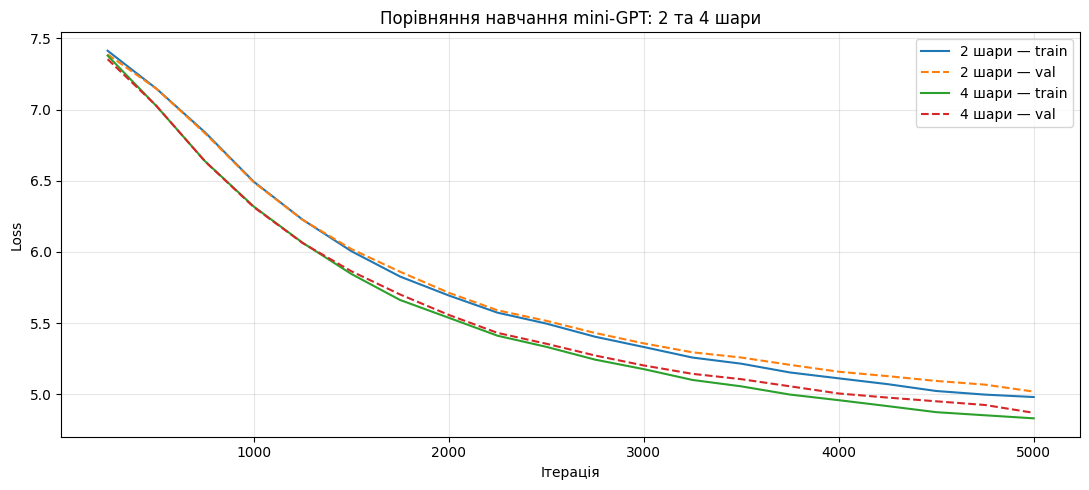

Порівняння результатів двох моделей:


,Модель,Кінцева train_loss,Кінцева val_loss,Найкраща val_loss,Найкраща ітерація
0,2 шари,4.9811,5.0192,5.0192,5000
1,4 шари,4.8315,4.8702,4.8702,5000


In [6]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

# Папка з результатами TensorBoard
TB_DIR = os.path.join(SAVE_DIR, "tensorboard")

# Завантажуємо історію навчання моделі
def load_training_history(run_name):
    log_path = os.path.join(TB_DIR, run_name)

    accumulator = EventAccumulator(
        log_path,
        size_guidance={"scalars": 0}
    )
    accumulator.Reload()

    train_events = accumulator.Scalars("loss/train")
    val_events = accumulator.Scalars("loss/val")

    assert len(train_events) == len(val_events)
    assert [e.step for e in train_events] == [
        e.step for e in val_events
    ]

    return {
        "steps": [e.step for e in train_events],
        "train": [e.value for e in train_events],
        "val": [e.value for e in val_events]
    }


# Завантажуємо результати двох моделей
history_2 = load_training_history("mini_gpt_2_layers")
history_4 = load_training_history("mini_gpt_4_layers")

# Будуємо спільний графік
plt.figure(figsize=(11, 5))

plt.plot(
    history_2["steps"],
    history_2["train"],
    label="2 шари — train",
    linestyle="-"
)

plt.plot(
    history_2["steps"],
    history_2["val"],
    label="2 шари — val",
    linestyle="--"
)

plt.plot(
    history_4["steps"],
    history_4["train"],
    label="4 шари — train",
    linestyle="-"
)

plt.plot(
    history_4["steps"],
    history_4["val"],
    label="4 шари — val",
    linestyle="--"
)

plt.xlabel("Ітерація")
plt.ylabel("Loss")
plt.title("Порівняння навчання mini-GPT: 2 та 4 шари")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Формуємо таблицю порівняння
comparison_rows = []

for name, history in [
    ("2 шари", history_2),
    ("4 шари", history_4)
]:
    best_idx = min(
        range(len(history["val"])),
        key=lambda i: history["val"][i]
    )

    comparison_rows.append({
        "Модель": name,
        "Кінцева train_loss": round(history["train"][-1], 4),
        "Кінцева val_loss": round(history["val"][-1], 4),
        "Найкраща val_loss": round(history["val"][best_idx], 4),
        "Найкраща ітерація": history["steps"][best_idx]
    })

models_comparison_df = pd.DataFrame(comparison_rows)

print("Порівняння результатів двох моделей:")
display(models_comparison_df)

Після навчання двох варіантів mini-GPT було побудовано спільний графік зміни `train_loss` і `val_loss` на основі результатів TensorBoard

На графіку видно, що помилки обох моделей поступово зменшувалися протягом 5 000 ітерацій. При цьому модель із чотирма шарами показала нижчі значення помилки порівняно з моделлю з двома шарами

Найкраща `val_loss` першої моделі становила 5.0192, а другої 4.8702. Водночас навчання моделі з чотирма шарами тривало довше: 3,14 хвилини проти 2,09 хвилини

Обидві моделі не показали помітних ознак перенавчання, оскільки навчальна та валідаційна помилки залишалися близькими

За результатами експерименту збільшення кількості шарів із 2 до 4 покращило валідаційну помилку, але потребувало більше часу на навчання

### **3.2.7. Продовжене навчання mini-GPT (4 шари)**

Оскільки після 5 000 ітерацій валідаційна помилка моделі з чотирма шарами продовжувала зменшуватися, було вирішено провести додатковий експеримент

Навчання продовжується зі збереженого чекпоінта до 15 000 ітерацій загалом. Для цього використовується попередній стан моделі та оптимізатора AdamW, тому починати навчання з нуля не потрібно

Кожні 250 ітерацій перевіряються навчальна та валідаційна помилки. Якщо валідаційна помилка перестане покращуватися протягом восьми перевірок поспіль, навчання завершиться достроково

Результати та чекпоінти зберігаються в окремій папці Google Drive, щоб не втратити початкову модель після 5 000 ітерацій

In [7]:
import os
import time
import shutil
import torch
from torch.utils.tensorboard import SummaryWriter

# Параметри продовженого навчання
EXT_N_LAYERS = 4
EXT_MAX_ITERS = 15000
EXT_LEARNING_RATE = 3e-4
EXT_EVAL_INTERVAL = 250
EXT_EVAL_ITERS = 50
PATIENCE = 8

assert torch.cuda.is_available(), "Для навчання потрібен GPU"

# Початкові чекпоінти після 5000 ітерацій
BASE_DIR = os.path.join(
    SAVE_DIR, "checkpoints", "mini_gpt_4_layers"
)

BASE_LAST = os.path.join(BASE_DIR, "last.pt")
BASE_BEST = os.path.join(BASE_DIR, "best.pt")

# Окремі папки для нового експерименту
EXT_NAME = "mini_gpt_4_layers_extended"

EXT_CHECKPOINT_DIR = os.path.join(
    SAVE_DIR, "checkpoints", EXT_NAME
)

EXT_LOG_DIR = os.path.join(
    SAVE_DIR, "tensorboard", EXT_NAME
)

os.makedirs(EXT_CHECKPOINT_DIR, exist_ok=True)
os.makedirs(EXT_LOG_DIR, exist_ok=True)

EXT_LAST = os.path.join(EXT_CHECKPOINT_DIR, "last.pt")
EXT_BEST = os.path.join(EXT_CHECKPOINT_DIR, "best.pt")

# Визначаємо, звідки продовжувати навчання
if os.path.isfile(EXT_LAST):
    checkpoint_path = EXT_LAST
    resumed = True
    print("Відновлюємо продовжене навчання")
else:
    assert os.path.isfile(BASE_LAST)
    assert os.path.isfile(BASE_BEST)

    checkpoint_path = BASE_LAST
    resumed = False

    # Зберігаємо початковий стан в окремій папці
    shutil.copy2(BASE_LAST, EXT_LAST)
    shutil.copy2(BASE_BEST, EXT_BEST)

    print("Починаємо продовження з 5000 ітерацій")

# Завантажуємо збережений стан
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

assert checkpoint["n_layers"] == EXT_N_LAYERS

# Створюємо модель і відновлюємо її параметри
extended_model = MiniGPT(
    vocab_size=GPT_VOCAB_SIZE,
    n_layers=EXT_N_LAYERS
).to(device)

extended_model.load_state_dict(
    checkpoint["model_state"]
)

extended_optimizer = torch.optim.AdamW(
    extended_model.parameters(),
    lr=EXT_LEARNING_RATE
)

extended_optimizer.load_state_dict(
    checkpoint["optimizer_state"]
)

# Відновлюємо результати попередніх ітерацій
start_step = checkpoint["step"]
best_val = checkpoint["best_val_loss"]
best_step = checkpoint["best_step"]

ext_steps = list(checkpoint["checkpoint_steps"])
ext_train_losses = list(checkpoint["train_losses"])
ext_val_losses = list(checkpoint["val_losses"])

no_improvement = checkpoint.get("no_improvement", 0)

assert start_step <= EXT_MAX_ITERS

# Функція перевірки помилки
@torch.no_grad()
def evaluate_extended(model):
    results = {}
    model.eval()

    for split in ["train", "val"]:
        losses = []

        for _ in range(EXT_EVAL_ITERS):
            x, y = get_batch(split)
            _, loss = model(x, y)
            losses.append(loss.item())

        results[split] = sum(losses) / len(losses)

    model.train()
    return results

# Функція збереження чекпоінтів
def save_extended(path, step):
    torch.save({
        "step": step,
        "n_layers": EXT_N_LAYERS,
        "max_iters": EXT_MAX_ITERS,
        "model_state": extended_model.state_dict(),
        "optimizer_state": extended_optimizer.state_dict(),
        "best_val_loss": best_val,
        "best_step": best_step,
        "checkpoint_steps": ext_steps,
        "train_losses": ext_train_losses,
        "val_losses": ext_val_losses,
        "no_improvement": no_improvement
    }, path)

# TensorBoard
writer = SummaryWriter(
    log_dir=EXT_LOG_DIR,
    purge_step=start_step + 1
)

# Додаємо попередні результати в новий журнал
if not resumed:
    for step, train_loss, val_loss in zip(
        ext_steps, ext_train_losses, ext_val_losses
    ):
        writer.add_scalar("loss/train", train_loss, step)
        writer.add_scalar("loss/val", val_loss, step)

    writer.flush()

torch.manual_seed(2027)

print("\nМодель:", EXT_NAME)
print("Початкова ітерація:", start_step)
print("Максимальна ітерація:", EXT_MAX_ITERS)
print(f"Початкова найкраща val_loss: {best_val:.4f}")
print("Пристрій:", device)
print("\nПродовження навчання\n")

start_time = time.time()
extended_model.train()

try:
    for step in range(start_step + 1, EXT_MAX_ITERS + 1):
        xb, yb = get_batch("train")

        _, loss = extended_model(xb, yb)

        extended_optimizer.zero_grad(set_to_none=True)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            extended_model.parameters(),
            max_norm=1.0
        )

        extended_optimizer.step()

        if step % EXT_EVAL_INTERVAL == 0:
            losses = evaluate_extended(extended_model)

            train_loss = losses["train"]
            val_loss = losses["val"]

            ext_steps.append(step)
            ext_train_losses.append(train_loss)
            ext_val_losses.append(val_loss)

            writer.add_scalar("loss/train", train_loss, step)
            writer.add_scalar("loss/val", val_loss, step)
            writer.flush()

            # Перевіряємо покращення
            improved = val_loss < best_val

            if improved:
                best_val = val_loss
                best_step = step
                no_improvement = 0
                save_extended(EXT_BEST, step)
            else:
                no_improvement += 1

            # Зберігаємо останній стан
            save_extended(EXT_LAST, step)

            print(
                f"Ітерація {step:5d} | "
                f"train_loss: {train_loss:.4f} | "
                f"val_loss: {val_loss:.4f} | "
                f"best: {best_val:.4f}"
            )

            # Дострокова зупинка
            if no_improvement >= PATIENCE:
                print("\nДострокова зупинка: "
                      "val_loss більше не покращується")
                break

except KeyboardInterrupt:
    print("\nНавчання зупинено вручну.")
    print("Збережено стан останньої перевірки.")

finally:
    writer.close()

elapsed_minutes = (time.time() - start_time) / 60

print("\nРезультати продовженого навчання:")
print("Остання збережена ітерація:", ext_steps[-1])
print("Найкраща ітерація:", best_step)
print(f"Найкраща val_loss: {best_val:.4f}")
print(f"Час поточного запуску: {elapsed_minutes:.2f} хв")
print("Папка чекпоінтів:", EXT_CHECKPOINT_DIR)
print("Папка TensorBoard:", EXT_LOG_DIR)

Починаємо продовження з 5000 ітерацій

Модель: mini_gpt_4_layers_extended
Початкова ітерація: 5000
Максимальна ітерація: 15000
Початкова найкраща val_loss: 4.8702
Пристрій: cuda

Продовження навчання

Ітерація  5250 | train_loss: 4.7991 | val_loss: 4.8447 | best: 4.8447
Ітерація  5500 | train_loss: 4.7936 | val_loss: 4.8373 | best: 4.8373
Ітерація  5750 | train_loss: 4.7576 | val_loss: 4.8187 | best: 4.8187
Ітерація  6000 | train_loss: 4.7374 | val_loss: 4.7979 | best: 4.7979
Ітерація  6250 | train_loss: 4.7009 | val_loss: 4.7631 | best: 4.7631
Ітерація  6500 | train_loss: 4.6953 | val_loss: 4.7572 | best: 4.7572
Ітерація  6750 | train_loss: 4.6625 | val_loss: 4.7276 | best: 4.7276
Ітерація  7000 | train_loss: 4.6620 | val_loss: 4.7039 | best: 4.7039
Ітерація  7250 | train_loss: 4.6388 | val_loss: 4.6909 | best: 4.6909
Ітерація  7500 | train_loss: 4.6306 | val_loss: 4.6738 | best: 4.6738
Ітерація  7750 | train_loss: 4.5985 | val_loss: 4.6743 | best: 4.6738
Ітерація  8000 | train_loss: 

Після завершення основного навчання було продовжено тренування mini-GPT із чотирма шарами трансформера з 5 000 до 15 000 ітерацій. Додаткове навчання тривало 6,03 хвилини на GPU

У результаті `train_loss` зменшилася з 4.8315 до 4.2606, а найкраща `val_loss` з 4.8702 до 4.3485. Це означає, що валідаційна помилка знизилася приблизно на 10,7%

Протягом додаткового навчання помилки продовжували зменшуватися, хоча спостерігалися невеликі коливання. Помітних ознак перенавчання не виявлено, а найкращий результат отримано на 15 000-й ітерації

Таким чином, продовження навчання дозволило покращити результати моделі без зміни її архітектури. Найкращий чекпоінт збережено окремо на Google Drive

### **3.2.8. Дослідження впливу подальшого навчання mini-GPT**

Після 15 000 ітерацій валідаційна помилка моделі продовжувала зменшуватися, тому було вирішено провести ще один експеримент і продовжити навчання до 20 000 ітерацій

Для цього використовується збережений стан чотиришарової mini-GPT та оптимізатора AdamW. Параметри моделі залишаються незмінними, а кожні 250 ітерацій перевіряються `train_loss` і `val_loss`

Також передбачено дострокову зупинку, якщо протягом восьми перевірок не буде помітного покращення. Результати зберігаються окремо, щоб можна було порівняти всі етапи навчання та повернутися до попередньої моделі за потреби


In [8]:
import os
import time
import shutil
import torch
from torch.utils.tensorboard import SummaryWriter

# Налаштування наступного експерименту
NEXT_MAX_ITERS = 20000
NEXT_N_LAYERS = 4
NEXT_LR = 3e-4
NEXT_EVAL_INTERVAL = 250
NEXT_EVAL_ITERS = 50

PATIENCE = 8
MIN_DELTA = 0.003

assert torch.cuda.is_available(), "Для навчання потрібен GPU"

# Чекпоінти після 15000 ітерацій
SOURCE_DIR = os.path.join(
    SAVE_DIR,
    "checkpoints",
    "mini_gpt_4_layers_extended"
)

SOURCE_LAST = os.path.join(SOURCE_DIR, "last.pt")
SOURCE_BEST = os.path.join(SOURCE_DIR, "best.pt")

# Окрема папка для нового експерименту
NEXT_NAME = "mini_gpt_4_layers_20000"

NEXT_DIR = os.path.join(
    SAVE_DIR, "checkpoints", NEXT_NAME
)

NEXT_LOG_DIR = os.path.join(
    SAVE_DIR, "tensorboard", NEXT_NAME
)

os.makedirs(NEXT_DIR, exist_ok=True)
os.makedirs(NEXT_LOG_DIR, exist_ok=True)

NEXT_LAST = os.path.join(NEXT_DIR, "last.pt")
NEXT_BEST = os.path.join(NEXT_DIR, "best.pt")

# Визначаємо початковий чекпоінт
if os.path.isfile(NEXT_LAST):
    checkpoint_path = NEXT_LAST
    resumed = True
    print("Відновлюємо поточний експеримент")

else:
    assert os.path.isfile(SOURCE_LAST)
    assert os.path.isfile(SOURCE_BEST)

    # Створюємо окремі копії чекпоінтів
    shutil.copy2(SOURCE_LAST, NEXT_LAST)
    shutil.copy2(SOURCE_BEST, NEXT_BEST)

    checkpoint_path = NEXT_LAST
    resumed = False

    print("Продовжуємо навчання з 15000 ітерацій")

# Завантажуємо чекпоінт
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

assert checkpoint["n_layers"] == NEXT_N_LAYERS

start_step = checkpoint["step"]

if not resumed:
    assert start_step == 15000

assert start_step <= NEXT_MAX_ITERS

# Створюємо модель
torch.manual_seed(2028)

next_model = MiniGPT(
    vocab_size=GPT_VOCAB_SIZE,
    n_layers=NEXT_N_LAYERS
).to(device)

next_model.load_state_dict(
    checkpoint["model_state"]
)

# Відновлюємо оптимізатор
next_optimizer = torch.optim.AdamW(
    next_model.parameters(),
    lr=NEXT_LR
)

next_optimizer.load_state_dict(
    checkpoint["optimizer_state"]
)

# Історія попереднього навчання
next_steps = list(checkpoint["checkpoint_steps"])
next_train_losses = list(checkpoint["train_losses"])
next_val_losses = list(checkpoint["val_losses"])

next_best_val = checkpoint["best_val_loss"]
next_best_step = checkpoint["best_step"]

# Для нового експерименту починаємо контроль заново
no_gain = checkpoint.get("no_gain", 0) if resumed else 0

# Відновлюємо генератор випадкових чисел
if resumed and "cpu_rng_state" in checkpoint:
    torch.set_rng_state(checkpoint["cpu_rng_state"])

    if torch.cuda.is_available() and "cuda_rng_state" in checkpoint:
        torch.cuda.set_rng_state_all(
            checkpoint["cuda_rng_state"]
        )

# Функція оцінювання помилок
@torch.no_grad()
def evaluate_next(model):
    results = {}
    model.eval()

    for split in ["train", "val"]:
        losses = []

        for _ in range(NEXT_EVAL_ITERS):
            x, y = get_batch(split)
            _, loss = model(x, y)
            losses.append(loss.item())

        results[split] = sum(losses) / len(losses)

    model.train()
    return results

# Функція збереження чекпоінта
def save_next(path, step):
    torch.save({
        "step": step,
        "n_layers": NEXT_N_LAYERS,
        "max_iters": NEXT_MAX_ITERS,
        "model_state": next_model.state_dict(),
        "optimizer_state": next_optimizer.state_dict(),
        "best_val_loss": next_best_val,
        "best_step": next_best_step,
        "checkpoint_steps": next_steps,
        "train_losses": next_train_losses,
        "val_losses": next_val_losses,
        "no_gain": no_gain,
        "cpu_rng_state": torch.get_rng_state(),
        "cuda_rng_state": torch.cuda.get_rng_state_all()
    }, path)

# Налаштування TensorBoard
writer = SummaryWriter(
    log_dir=NEXT_LOG_DIR,
    purge_step=start_step + 1
)

# Додаємо попередню історію в новий журнал
if not resumed:
    for step, train_loss, val_loss in zip(
        next_steps,
        next_train_losses,
        next_val_losses
    ):
        writer.add_scalar("loss/train", train_loss, step)
        writer.add_scalar("loss/val", val_loss, step)

    writer.flush()

print("\nМодель:", NEXT_NAME)
print("Початкова ітерація:", start_step)
print("Максимальна ітерація:", NEXT_MAX_ITERS)
print(f"Початкова найкраща val_loss: {next_best_val:.4f}")
print("Пристрій:", device)
print("\nПочаток навчання\n")

start_time = time.time()
next_model.train()

try:
    for step in range(start_step + 1, NEXT_MAX_ITERS + 1):

        xb, yb = get_batch("train")

        _, loss = next_model(xb, yb)

        next_optimizer.zero_grad(set_to_none=True)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            next_model.parameters(),
            max_norm=1.0
        )

        next_optimizer.step()

        # Оцінювання кожні 250 ітерацій
        if step % NEXT_EVAL_INTERVAL == 0:

            losses = evaluate_next(next_model)

            train_loss = losses["train"]
            val_loss = losses["val"]

            next_steps.append(step)
            next_train_losses.append(train_loss)
            next_val_losses.append(val_loss)

            writer.add_scalar(
                "loss/train", train_loss, step
            )
            writer.add_scalar(
                "loss/val", val_loss, step
            )
            writer.flush()

            # Перевіряємо величину покращення
            improvement = next_best_val - val_loss

            if improvement > MIN_DELTA:
                no_gain = 0
            else:
                no_gain += 1

            # Найкраща модель зберігається
            # навіть за невеликого покращення
            if val_loss < next_best_val:
                next_best_val = val_loss
                next_best_step = step
                save_next(NEXT_BEST, step)

            # Зберігаємо останній стан
            save_next(NEXT_LAST, step)

            print(
                f"Ітерація {step:5d} | "
                f"train_loss: {train_loss:.4f} | "
                f"val_loss: {val_loss:.4f} | "
                f"best: {next_best_val:.4f}"
            )

            # Дострокова зупинка
            if no_gain >= PATIENCE:
                print(
                    "\nДострокова зупинка: "
                    "помітного покращення немає"
                )
                break

except KeyboardInterrupt:
    print("\nНавчання зупинено вручну")
    print("Можна відновити з останнього чекпоінта")

finally:
    writer.close()

elapsed = (time.time() - start_time) / 60

print("\nРезультати експерименту:")
print("Остання збережена ітерація:", next_steps[-1])
print("Найкраща ітерація:", next_best_step)
print(f"Найкраща val_loss: {next_best_val:.4f}")
print(f"Час поточного запуску: {elapsed:.2f} хв")
print("Папка чекпоінтів:", NEXT_DIR)
print("Папка TensorBoard:", NEXT_LOG_DIR)

Продовжуємо навчання з 15000 ітерацій

Модель: mini_gpt_4_layers_20000
Початкова ітерація: 15000
Максимальна ітерація: 20000
Початкова найкраща val_loss: 4.3485
Пристрій: cuda

Початок навчання

Ітерація 15250 | train_loss: 4.2719 | val_loss: 4.3687 | best: 4.3485
Ітерація 15500 | train_loss: 4.2788 | val_loss: 4.3490 | best: 4.3485
Ітерація 15750 | train_loss: 4.2579 | val_loss: 4.3457 | best: 4.3457
Ітерація 16000 | train_loss: 4.2307 | val_loss: 4.3229 | best: 4.3229
Ітерація 16250 | train_loss: 4.2572 | val_loss: 4.3219 | best: 4.3219
Ітерація 16500 | train_loss: 4.2234 | val_loss: 4.3307 | best: 4.3219
Ітерація 16750 | train_loss: 4.2245 | val_loss: 4.3239 | best: 4.3219
Ітерація 17000 | train_loss: 4.1965 | val_loss: 4.3144 | best: 4.3144
Ітерація 17250 | train_loss: 4.2047 | val_loss: 4.2963 | best: 4.2963
Ітерація 17500 | train_loss: 4.2162 | val_loss: 4.3247 | best: 4.2963
Ітерація 17750 | train_loss: 4.2029 | val_loss: 4.2931 | best: 4.2931
Ітерація 18000 | train_loss: 4.1918

У результаті найкраща val_loss зменшилася з 4.3485 до 4.2366, тобто приблизно на 2,57%. Найкращий результат отримано на 19 500-й ітерації

Наприкінці навчання валідаційна помилка почала коливатися, а покращення стало меншим, ніж під час попереднього експерименту. Водночас явного перенавчання не виявлено

Подальше навчання покращило результат моделі, але для оцінювання її якості потрібно також перевірити згенерований текст. Найкращий чекпоінт було збережено на Google Drive

### **3.3.1. Генерація тексту за допомогою навчених моделей**

Для перевірки якості mini-GPT використовуємо найкращі чекпоінти моделей, збережені після різних етапів навчання

Генерація виконується за однаковим початковим текстом і з однаковими налаштуваннями. Порівнюємо модель із двома шарами після 5 000 ітерацій та модель із чотирма шарами після 5 000, 15 000 і 19 500 ітерацій

Це дозволить перевірити, чи покращення валідаційної помилки супроводжується більш зрозумілим і зв'язним текстом

In [9]:
import os
import torch
import torch.nn.functional as F

# Однаковий промпт для всіх моделей
PROMPT = "У Житомирі сьогодні"

# Налаштування генерації
MAX_NEW_TOKENS = 150
TEMPERATURE = 0.8
TOP_K = 40
SEED = 42

# Найкращі чекпоінти різних етапів
models_to_test = [
    ("2 шари — 5000 ітерацій",
     "mini_gpt_2_layers", 2),

    ("4 шари — 5000 ітерацій",
     "mini_gpt_4_layers", 4),

    ("4 шари — 15000 ітерацій",
     "mini_gpt_4_layers_extended", 4),

    ("4 шари — найкраща після 20000",
     "mini_gpt_4_layers_20000", 4)
]

# Функція генерації тексту
@torch.no_grad()
def generate_text(model, prompt, max_new_tokens=150):
    model.eval()

    # Перетворюємо промпт на ID токенів
    token_ids = gpt_tokenizer.encode(prompt).ids

    idx = torch.tensor(
        [token_ids],
        dtype=torch.long,
        device=device
    )

    eos_id = gpt_tokenizer.token_to_id("<eos>")
    unk_id = gpt_tokenizer.token_to_id("<unk>")

    # Однаковий seed для порівняння
    generator = torch.Generator(device=device)
    generator.manual_seed(SEED)

    for _ in range(max_new_tokens):
        # Використовуємо останні 64 токени
        idx_cond = idx[:, -CONTEXT_LEN:]

        logits, _ = model(idx_cond)

        # Беремо прогноз для наступного токена
        next_logits = logits[:, -1, :] / TEMPERATURE

        # Забороняємо генерувати невідомий токен
        next_logits[:, unk_id] = float("-inf")

        # Залишаємо TOP_K найімовірніших токенів
        values, indices = torch.topk(
            next_logits,
            k=min(TOP_K, next_logits.size(-1))
        )

        probabilities = F.softmax(values, dim=-1)

        sampled_pos = torch.multinomial(
            probabilities,
            num_samples=1,
            generator=generator
        )

        next_token = indices.gather(1, sampled_pos)

        # Завершуємо генерацію після <eos>
        if next_token.item() == eos_id:
            break

        idx = torch.cat([idx, next_token], dim=1)

    # Перетворюємо токени на звичайний текст
    return gpt_tokenizer.decode(
        idx[0].tolist(),
        skip_special_tokens=True
    )


# Генеруємо текст кожною моделлю
generation_results = {}

for model_name, folder_name, n_layers in models_to_test:

    checkpoint_path = os.path.join(
        SAVE_DIR,
        "checkpoints",
        folder_name,
        "best.pt"
    )

    assert os.path.isfile(checkpoint_path), (
        f"Не знайдено чекпоінт: {checkpoint_path}"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    assert checkpoint["n_layers"] == n_layers

    # Відновлюємо модель
    test_model = MiniGPT(
        vocab_size=GPT_VOCAB_SIZE,
        n_layers=n_layers
    ).to(device)

    test_model.load_state_dict(
        checkpoint["model_state"]
    )

    # Генеруємо текст
    generated = generate_text(
        test_model,
        PROMPT,
        MAX_NEW_TOKENS
    )

    generation_results[model_name] = generated

    print("=" * 65)
    print("Модель:", model_name)
    print("Ітерація чекпоінта:", checkpoint["step"])
    print(f"Найкраща val_loss: {checkpoint['best_val_loss']:.4f}")
    print("Промпт:", PROMPT)

    print("\nЗгенерований текст:")
    print(generated)
    print()

    # Звільняємо пам'ять GPU
    del test_model, checkpoint

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("Генерацію всіма моделями завершено")

Модель: 2 шари — 5000 ітерацій
Ітерація чекпоінта: 5000
Найкраща val_loss: 5.0192
Промпт: У Житомирі сьогодні

Згенерований текст:
У Житомирі сьогодні, що внаслідок атаки по житловому та Дніпропетровській області.
Слуговують на канали OBOZ.UA, що Росія знову атакували Київщину, які в обмін атаки дронів, а також «Східну, і діло».
Ключовим словами, що є "Законолітних мужоїдиціонерів, що вигадує й в Україні для боротьби, а також в країні, але це з іншими людей та безпеки.
"Доповні новини тут було пошкоджено чотири грудня 2025 року, але не зеруть й у разі необхідності. Він пояснив, які були і на посаду керівника Офісу президента України. Далі для досягнення угоди.
Суполярівнянської доби, щоб відстежувати найцікавіші новини у соцмережах.


Модель: 4 шари — 5000 ітерацій
Ітерація чекпоінта: 5000
Найкраща val_loss: 4.8702
Промпт: У Житомирі сьогодні

Згенерований текст:
У Житомирі сьогодні, що Росія не було ухвалених для збереженнях.
- Крім того, як ми продовжувати в нас уважний час.
- Звариб

Під час перевірки було згенеровано тексти чотирма версіями mini-GPT за однаковим промптом «У Житомирі сьогодні». Для всіх моделей використовувалися однакові налаштування генерації

Перші дві моделі після 5 000 ітерацій створювали текст із великою кількістю граматичних помилок, незрозумілих слів та порушень змісту. Після 15 000 ітерацій у тексті почали частіше з'являтися зв'язніші фрагменти та характерні для новин вислови

Найкращий результат серед перевірених прикладів показала модель із чотирма шарами після 19 500 ітерацій, яка мала найменшу `val_loss` 4.2366. Її текст більше нагадував новинне повідомлення, хоча все ще містив повторення, граматичні помилки та нелогічні переходи між подіями

Порівняння показало, що зменшення валідаційної помилки супроводжувалося покращенням структури згенерованого тексту. Водночас модель ще не створює повністю зв'язні повідомлення, тому її результати потребують подальшого вдосконалення

### **3.3.2. Дослідження впливу temperature та top_k на генерацію тексту**

Для додаткової перевірки використовується найкраща чотиришарова mini-GPT після 19 500 ітерацій навчання

Проводимо експеримент із різними значеннями `temperature` та `top_k`, не змінюючи саму модель. Параметр `temperature` впливає на випадковість вибору наступного токена, а `top_k` обмежує кількість можливих токенів під час генерації

Спочатку порівнюємо три значення температури за однакового `top_k`, а потім змінюємо `top_k` за фіксованої температури. Для всіх запусків використовується однаковий промпт «У Житомирі сьогодні»

Це дозволить перевірити, чи можна покращити зрозумілість і зв'язність тексту без додаткового навчання моделі

In [10]:
import os
import json
import torch
import torch.nn.functional as F

# Найкращий чекпоінт після 20000 ітерацій
checkpoint_path = os.path.join(
    SAVE_DIR,
    "checkpoints",
    "mini_gpt_4_layers_20000",
    "best.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

# Відновлюємо найкращу модель
best_model = MiniGPT(
    vocab_size=GPT_VOCAB_SIZE,
    n_layers=4
).to(device)

best_model.load_state_dict(
    checkpoint["model_state"]
)

best_model.eval()

# Спільні налаштування
TEST_PROMPT = "У Житомирі сьогодні"
MAX_NEW_TOKENS = 150
TEST_SEED = 42

# Параметри для порівняння
settings = [
    (0.8, 40),
    (0.6, 40),
    (0.4, 40),
    (0.6, 20),
    (0.6, 10)
]

@torch.no_grad()
def generate_with_settings(
    model, prompt, temperature, top_k
):
    token_ids = gpt_tokenizer.encode(prompt).ids

    idx = torch.tensor(
        [token_ids],
        dtype=torch.long,
        device=device
    )

    eos_id = gpt_tokenizer.token_to_id("<eos>")
    unk_id = gpt_tokenizer.token_to_id("<unk>")

    # Однаковий seed для кожного запуску
    generator = torch.Generator(device=device)
    generator.manual_seed(TEST_SEED)

    for _ in range(MAX_NEW_TOKENS):
        idx_cond = idx[:, -CONTEXT_LEN:]

        logits, _ = model(idx_cond)

        # Регулюємо температуру
        next_logits = logits[:, -1, :] / temperature

        # Не дозволяємо генерувати <unk>
        next_logits[:, unk_id] = float("-inf")

        # Обмежуємо вибір найімовірнішими токенами
        values, indices = torch.topk(
            next_logits,
            k=min(top_k, next_logits.size(-1))
        )

        probabilities = F.softmax(values, dim=-1)

        sampled_pos = torch.multinomial(
            probabilities,
            num_samples=1,
            generator=generator
        )

        next_token = indices.gather(1, sampled_pos)

        if next_token.item() == eos_id:
            break

        idx = torch.cat([idx, next_token], dim=1)

    return gpt_tokenizer.decode(
        idx[0].tolist(),
        skip_special_tokens=True
    )


# Проводимо експерименти
generation_tests = []

print("Ітерація чекпоінта:", checkpoint["step"])
print("Найкраща val_loss:",
      round(checkpoint["best_val_loss"], 4))
print("Промпт:", TEST_PROMPT)

for temperature, top_k in settings:

    text = generate_with_settings(
        best_model,
        TEST_PROMPT,
        temperature,
        top_k
    )

    generation_tests.append({
        "temperature": temperature,
        "top_k": top_k,
        "text": text
    })

    print("\n" + "=" * 65)
    print(f"temperature={temperature}, top_k={top_k}")
    print("\nЗгенерований текст:")
    print(text)

# Зберігаємо результати в Google Drive
RESULTS_DIR = os.path.join(
    SAVE_DIR, "generation_experiments"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

RESULTS_PATH = os.path.join(
    RESULTS_DIR, "temperature_topk.json"
)

with open(RESULTS_PATH, "w", encoding="utf-8") as f:
    json.dump(
        generation_tests,
        f,
        ensure_ascii=False,
        indent=2
    )

print("\nЕксперименти завершено")
print("Результати збережено:", RESULTS_PATH)

Ітерація чекпоінта: 19500
Найкраща val_loss: 4.2366
Промпт: У Житомирі сьогодні

temperature=0.8, top_k=40

Згенерований текст:
У Житомирі сьогодні, у разі повторної тривоги у відповідь на війну з боку Росії.
У ніч проти 9 січня Росія атакувала Україну 9 січня, у ніч на 31 грудня 3 січня, внаслідок чого постраждало вибухи, а в Одесі зафіксовано влучання FPV-лиск.
- Внаслідок атаки на Дніпропетровщині поранено в Одеській області.
- Внаслідок атаки в області росіяни завдали об'єкт критичної інфраструктури, серед них — зокрема в Дніпропетровській та Дніпропетровській областях.
- Внаслідок масованої атаки пошкоджено поранень внаслідок ворожого удару по столиці, пошкоджено автомобільних об’єктах.
- БпЛА на Сумському напрямку БпЛА. БпЛА на Харківщині, Чернігівській, Одеській областях. Унаслідок атаки пошкоджено об’єкти критичної інфраструктури. Внаслідок атаки пошкоджено загинуло щонайменше на місці.

temperature=0.6, top_k=40

Згенерований текст:
У Житомирі сьогодні, у разі повторної тривог

Під час експерименту було перевірено п'ять комбінацій параметрів `temperature` та `top_k` на найкращій чотиришаровій mini-GPT після 19 500 ітерацій

За вищої температури текст був різноманітнішим, проте містив багато нелогічних і граматично неправильних конструкцій. Зменшення температури та `top_k` зробило генерацію більш передбачуваною, але також посилило повторення окремих слів і висловів

Серед перевірених прикладів найбільш вдалим виявилося поєднання `temperature = 0.6` і `top_k = 10`. Текст більше нагадував коротке новинне зведення, хоча все ще містив повторення та порушення логіки

Експеримент показав, що зміна налаштувань генерації впливає на вигляд тексту без додаткового навчання моделі. Проте навіть найкращий із перевірених варіантів не забезпечив повністю зв'язного результату

### **3.3.3. Загальний висновок до завдання №3**

У ході виконання завдання було підготовлено власний корпус із 20 000 українських новинних статей, навчено BPE-токенізатор зі словником на 8 000 токенів та створено два варіанти mini-GPT із двома й чотирма шарами трансформера

Спочатку обидві моделі навчалися протягом 5 000 ітерацій. Модель із чотирма шарами показала кращий результат: `val_loss` становила 4.8702 проти 5.0192 у двошарової моделі. Водночас її навчання потребувало більше часу

Також це порівняння показало, що в наших експериментах найбільше на зменшення `val_loss` вплинуло продовження навчання. Збільшення кількості шарів із двох до чотирьох при 5 000 ітерацій зменшило помилку приблизно на 3%. Натомість продовження навчання чотиришарової моделі до 20 000 ітерацій дало зниження ще приблизно на 13%

Водночас двошарову модель навчали лише 5 000 ітерацій, тому ми не можемо точно сказати, якою була б різниця між моделями після однаково тривалого навчання. Розмір словника та довжину контексту також не змінювали, тому їхній вплив окремо не перевіряли

Оскільки валідаційна помилка продовжувала зменшуватися, навчання чотиришарової моделі було продовжено до 15 000, а потім до 20 000 ітерацій. Найкращу `val_loss = 4.2366` отримано на 19 500-й ітерації

Після цього було перевірено генерацію тексту за однаковим промптом. Зі збільшенням тривалості навчання модель краще відтворювала новинний стиль, хоча речення все ще містили граматичні помилки, повторення та нелогічні переходи

Додатково перевірено вплив параметрів `temperature` і `top_k`. Серед отриманих прикладів найбільш вдалим виявився варіант із `temperature = 0.6` та `top_k = 10`, який більше нагадував коротке новинне повідомлення

За результатами експериментів найкращою було обрано чотиришарову mini-GPT із чекпоінтом після 19 500 ітерацій. Подальше навчання вирішено завершити, оскільки покращення валідаційної помилки поступово сповільнювалося, а для суттєвого підвищення якості тексту можуть знадобитися зміни архітектури, довжини контексту або підготовки даних

Отримані результати показали, як кількість шарів, тривалість навчання та параметри генерації впливають на роботу власної мовної моделі

### **3.4. Підготовка результатів до збереження**

Після завершення експериментів було перевірено наявність збережених моделей mini-GPT, токенізатора та логів навчання. Це потрібно для подальшого оформлення лабораторної роботи й використання отриманих результатів без повторного навчання моделей.

In [25]:
from pathlib import Path
from google.colab import drive

# Підключаємо Google Drive
drive.mount("/content/drive")

# Папка з результатами завдання №3
save_dir = Path("/content/drive/MyDrive/mini_gpt_news")

# Усі чотири експерименти
runs = {
    "minigpt_v1": "mini_gpt_2_layers",
    "minigpt_v2": "mini_gpt_4_layers",
    "minigpt_v3": "mini_gpt_4_layers_extended",
    "minigpt_v4": "mini_gpt_4_layers_20000",
}

print("Перевірка збережених моделей:\n")

all_files_found = True

for model_name, run_name in runs.items():
    checkpoint = save_dir / "checkpoints" / run_name / "best.pt"
    log_dir = save_dir / "tensorboard" / run_name

    checkpoint_exists = checkpoint.is_file()
    log_exists = log_dir.is_dir() and any(log_dir.iterdir())

    if not checkpoint_exists or not log_exists:
        all_files_found = False

    print(f"{model_name} ({run_name}):")
    print("  Чекпоінт:", "Знайдено" if checkpoint_exists else "НЕ ЗНАЙДЕНО")
    print("  Логи:", "Знайдено" if log_exists else "НЕ ЗНАЙДЕНО")

# Перевірка токенізатора та навчальних даних
print("\nДодаткові файли:")

for filename in ["tokenizer.json", "train_ids.npy", "val_ids.npy"]:
    file_exists = (save_dir / filename).is_file()

    if not file_exists:
        all_files_found = False

    print(filename, "—", "Знайдено" if file_exists else "НЕ ЗНАЙДЕНО")

print("\nРезультат перевірки:")

if all_files_found:
    print("Усі основні файли завдання №3 знайдено.")
else:
    print("Деякі файли відсутні. Потрібно перевірити шляхи.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Перевірка збережених моделей:

minigpt_v1 (mini_gpt_2_layers):
  Чекпоінт: Знайдено
  Логи: Знайдено
minigpt_v2 (mini_gpt_4_layers):
  Чекпоінт: Знайдено
  Логи: Знайдено
minigpt_v3 (mini_gpt_4_layers_extended):
  Чекпоінт: Знайдено
  Логи: Знайдено
minigpt_v4 (mini_gpt_4_layers_20000):
  Чекпоінт: Знайдено
  Логи: Знайдено

Додаткові файли:
tokenizer.json — Знайдено
train_ids.npy — Знайдено
val_ids.npy — Знайдено

Результат перевірки:
Усі основні файли завдання №3 знайдено.


Під час перевірки було знайдено всі чотири збережені моделі mini-GPT та відповідні логи навчання. Також підтверджено наявність токенізатора й файлів із підготовленими даними. Отже, результати попередніх експериментів збережені на Google Drive і можуть використовуватися без повторного навчання моделей

### 3.5. **Збереження моделей і логів навчання**

Для підготовки лабораторної роботи до здачі було створено окремі папки для навчених моделей та логів TensorBoard. У них зберігаються результати чотирьох експериментів mini-GPT, щоб надалі їх можна було додати до репозиторію

In [26]:
from pathlib import Path
import shutil

# Папка з результатами на Google Drive
save_dir = Path("/content/drive/MyDrive/mini_gpt_news")

# Папка для підготовки лабораторної роботи
lab_dir = save_dir / "lab3"

models_dir = lab_dir / "models"
runs_dir = lab_dir / "runs"

models_dir.mkdir(parents=True, exist_ok=True)
runs_dir.mkdir(parents=True, exist_ok=True)

# Варіанти навчених моделей
runs = {
    "minigpt_v1": "mini_gpt_2_layers",
    "minigpt_v2": "mini_gpt_4_layers",
    "minigpt_v3": "mini_gpt_4_layers_extended",
    "minigpt_v4": "mini_gpt_4_layers_20000",
}

for model_name, run_name in runs.items():
    # Шляхи до оригінальних файлів
    source_model = save_dir / "checkpoints" / run_name / "best.pt"
    source_logs = save_dir / "tensorboard" / run_name

    # Шляхи для здачі
    target_model = models_dir / f"{model_name}.pt"
    target_logs = runs_dir / run_name

    # Перевірка оригінальних файлів
    assert source_model.is_file(), f"Не знайдено {source_model}"
    assert source_logs.is_dir(), f"Не знайдено {source_logs}"

    # Не перезаписуємо вже підготовлені файли
    if not target_model.exists():
        shutil.copy2(source_model, target_model)

    if not target_logs.exists():
        shutil.copytree(source_logs, target_logs)

    print(f"{model_name}: модель і логи збережено")

print("\nПапка лабораторної:", lab_dir)
print("Копіювання завершено")

minigpt_v1: модель і логи збережено
minigpt_v2: модель і логи збережено
minigpt_v3: модель і логи збережено
minigpt_v4: модель і логи збережено

Папка лабораторної: /content/drive/MyDrive/mini_gpt_news/lab3
Копіювання завершено


Було створено папки `models` та `runs` відповідно до вимог лабораторної роботи. До них скопійовано чотири збережені моделі mini-GPT та логи їхнього навчання. Копіювання виконано успішно, тому результати можна буде використати для підготовки репозиторію без повторного навчання

### **3.6. Збереження результатів порівняння моделей**

Для подальшого порівняння навчених моделей було підготовлено таблицю з найкращими значеннями `val_loss` та ітераціями, на яких їх отримано. Результати зберігаються у файлі `results.csv`, який буде доповнено під час виконання завдання №5.

In [27]:
from pathlib import Path
import pandas as pd
import torch

# Папки з результатами
save_dir = Path("/content/drive/MyDrive/mini_gpt_news")
lab_dir = save_dir / "lab3"
models_dir = lab_dir / "models"
csv_path = lab_dir / "results.csv"

# Зчитуємо результати зі збережених чекпоінтів
model_variants = {
    "minigpt_v1": "2 шари, 5000 ітерацій",
    "minigpt_v2": "4 шари, 5000 ітерацій",
    "minigpt_v3": "4 шари, 15000 ітерацій",
    "minigpt_v4": "4 шари, 20000 ітерацій",
}

rows = []

for model_name, description in model_variants.items():
    checkpoint_path = models_dir / f"{model_name}.pt"

    assert checkpoint_path.is_file(), f"Файл не знайдено: {checkpoint_path}"

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    rows.append({
        "model": model_name,
        "variant": description,
        "best_val_loss": round(float(checkpoint["best_val_loss"]), 4),
        "best_step": int(checkpoint["best_step"]),
    })

# Створення CSV-файлу
results_df = pd.DataFrame(rows)

results_df.to_csv(
    csv_path,
    index=False,
    encoding="utf-8-sig"
)

print("Файл створено:", csv_path)
display(results_df)

Файл створено: /content/drive/MyDrive/mini_gpt_news/lab3/results.csv


,model,variant,best_val_loss,best_step
0,minigpt_v1,"2 шари, 5000 ітерацій",5.0192,5000
1,minigpt_v2,"4 шари, 5000 ітерацій",4.8702,5000
2,minigpt_v3,"4 шари, 15000 ітерацій",4.3485,15000
3,minigpt_v4,"4 шари, 20000 ітерацій",4.2366,19500


Було створено файл `results.csv`, до якого записано результати чотирьох варіантів mini-GPT. Найменше значення `val_loss` отримала модель `minigpt_v4`  4,2366 на 19 500-й ітерації. Файл збережено в папці `lab3` для подальшого використання та доповнення результатами завдання №5

### **3.7. Перевірка підготовлених файлів**

Після копіювання моделей і логів було перевірено структуру папки `lab3`, наявність чотирьох файлів моделей, логів TensorBoard та таблиці результатів. Це потрібно, щоб переконатися, що файли для здачі лабораторної роботи підготовлено правильно.

In [28]:
from pathlib import Path
import pandas as pd

lab_dir = Path("/content/drive/MyDrive/mini_gpt_news/lab3")

models = [
    "minigpt_v1.pt",
    "minigpt_v2.pt",
    "minigpt_v3.pt",
    "minigpt_v4.pt",
]

runs = [
    "mini_gpt_2_layers",
    "mini_gpt_4_layers",
    "mini_gpt_4_layers_extended",
    "mini_gpt_4_layers_20000",
]

all_ok = True

print("Перевірка моделей:")
for name in models:
    path = lab_dir / "models" / name
    ok = path.is_file() and path.stat().st_size > 0
    print(f"  {name}: {'OK' if ok else 'ПОМИЛКА'}")
    all_ok &= ok

print("\nПеревірка логів:")
for name in runs:
    path = lab_dir / "runs" / name
    event_files = list(path.rglob("events.out.tfevents.*")) if path.is_dir() else []
    ok = any(f.stat().st_size > 0 for f in event_files)
    print(f"  {name}: {'OK' if ok else 'ПОМИЛКА'}")
    all_ok &= ok

print("\nПеревірка results.csv:")
csv_path = lab_dir / "results.csv"
csv_ok = csv_path.is_file() and csv_path.stat().st_size > 0

if csv_ok:
    df = pd.read_csv(csv_path)
    csv_ok = len(df) == 4 and set(df["model"]) == {
        "minigpt_v1", "minigpt_v2", "minigpt_v3", "minigpt_v4"
    }

print("  results.csv:", "OK" if csv_ok else "ПОМИЛКА")
all_ok &= csv_ok

print("\nПідсумок:")
print("Усі файли завдання №3 підготовлено." if all_ok
      else "Потрібно виправити відсутні або некоректні файли.")

Перевірка моделей:
  minigpt_v1.pt: OK
  minigpt_v2.pt: OK
  minigpt_v3.pt: OK
  minigpt_v4.pt: OK

Перевірка логів:
  mini_gpt_2_layers: OK
  mini_gpt_4_layers: OK
  mini_gpt_4_layers_extended: OK
  mini_gpt_4_layers_20000: OK

Перевірка results.csv:
  results.csv: OK

Підсумок:
Усі файли завдання №3 підготовлено.


---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

_Зверніть увагу_: в межах попередніх завдань Ви могли завантажити памʼять "під завʼязку", тому для безпроблемного виконання наступних секцій вивільніть памʼять:

1. **Спершу збережіть усе потрібне на диск** — чекпоінти mini-GPT (`models/minigpt_v*.pt`), токенізатори, `results.csv`. Секції 4-6 від змінних секцій 1-3 не залежать, тож після цього їх можна сміливо видаляти.
2. **Видаліть великі обʼєкти** — моделі, оптимізатори, тензори `train_data`/`val_data`, корпус і `DataFrame`-и — і зберіть сміття:
   ```python
   import gc, torch

   del model, optimizer, train_data, val_data, corpus_text  # підставте свої імена змінних
   gc.collect()
   if torch.cuda.is_available():
       torch.cuda.empty_cache()
       print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
   ```
   Памʼять звільниться лише тоді, коли на обʼєкт не лишиться **жодного** посилання: зверніть увагу на копії в інших змінних, списках і словниках (наприклад, словник із кількома варіантами моделей).
3. **Перевірте, що памʼять справді звільнилась**: індикатор RAM/GPU вгорі праворуч.
4. **У самій секції 4 не тримайте всі pipeline-и одночасно**: кожен `pipeline(...)` завантажує окрему модель. Перевикористовуйте одну змінну (як `classifier` нижче) або робіть `del` + `gc.collect()` після кожної задачі.
5. **Стежте за диском**: моделі кешуються в `~/.cache/huggingface/hub`, і кілька моделей для summarization/translation легко займуть кілька ГБ. Переглянути й почистити кеш: `hf cache ls` / `hf cache rm <id моделі>`.

## 4.0. Запустіть приклади виконання різних NLP задач

Було встановлено бібліотеку transformers версії 5.18.0 разом із необхідними залежностями

In [24]:
!pip install "transformers[sentencepiece]==5.18.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 42.2 MB/s  0:00:00
  Attempting uninstall: transformers
    Found existing installation: transformers 5.20.2
    Uninstalling transformers-5.20.2:
      Successfully uninstalled transformers-5.20.2


### ***4.0.1. Аналіз тональності тексту (Sentiment Analysis)***

Для початку було використано готову модель `pipeline("sentiment-analysis")`, яка визначає позитивне або негативне забарвлення тексту. Її роботу перевірено на реченнях із прикладу Hugging Face.

In [29]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
))

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9598048329353333}]
[{'label': 'POSITIVE', 'score': 0.9598048329353333}, {'label': 'NEGATIVE', 'score': 0.9994558691978455}]


Модель правильно визначила тональність обох речень. Перше вона віднесла до позитивних із впевненістю 95,98%, а друге до негативних із впевненістю 99,95%. Отже, на цих прикладах `pipeline("sentiment-analysis")` працює правильно та дозволяє визначати емоційне забарвлення тексту

### ***4.0.2. Класифікація тексту за заданими категоріями (Zero-shot Classification)***

Наступним кроком було перевірено класифікацію тексту за допомогою `pipeline("zero-shot-classification")`. Моделі передається речення про бібліотеку Transformers та три можливі категорії: освіта, політика й бізнес. Потрібно визначити, до якої з них текст найбільше підходить.

In [30]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification")
classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"],
)

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.8445985913276672, 0.11197450757026672, 0.04342687129974365]}

Модель визначила, що речення найбільше відповідає категорії освіти, яка отримала оцінку 84,46%. Для бізнесу результат становив 11,20%, а для політики 4,34%. Отриманий результат відповідає змісту речення, оскільки в ньому йдеться про навчальний курс. Модель правильно обрала найбільш відповідну категорію серед запропонованих

### ***4.0.3. Генерація тексту (Text Generation)***

Далі було перевірено генерацію тексту за допомогою `pipeline("text-generation")`. Модель отримує початок речення про навчальний курс і має самостійно його продовжити. Для перевірки використано стандартну модель та `distilgpt2`, як у прикладі Hugging Face

In [31]:
# Text generation
from transformers import pipeline

generator = pipeline("text-generation")
print(generator("In this course, we will teach you how to"))

generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_length=30,
    num_return_sequences=2,
))

[transformers] No model was supplied, defaulted to HuggingFaceTB/SmolLM3-3B and revision a07cc9a.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/26.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/326 [00:00<?, ?it/s]

... (15 outputs left out)

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'num_return_sequences', 'max_length'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': 'In this course, we will teach you how to create a more complex and powerful online environment.\n\n\n\nLearning online is a great way to learn about life online, and it is vital that you study online and learn about how to learn online.\nNow in a new book, we will teach you how to create a more complex online environment.\nThis book will show you how to create a more complex online environment.\nIt begins with the question: What can you do?\nThe answer is that you can create a more complex online environment, and then you can create a more complex online environment.\nThis is a great way to learn about the world online and learn about how to create a more complex online environment.\nIf you are interested in learning about online, check out the book.\nYou can also learn about how to create a more complex online environment.\nThis book is an exciting read!'}, {'generated_text': 'In this course, we will teach you how to install and configure your own apps and service

Під час виконання прикладу було перевірено генерацію тексту за допомогою двох готових моделей. Стандартна модель `SmolLM3-3B` продовжила речення розповіддю про створення гри на Python, а `distilgpt2` згенерувала текст про онлайн-навчання. Обидві моделі змогли продовжити початкове речення, проте запропонували різні за змістом варіанти. Результати показали, що навіть за однакового початку тексту різні мовні моделі можуть формувати різні продовження

### ***4.0.4. Заповнення пропусків у тексті (Fill-Mask)***

Наступним кроком було перевірено роботу `pipeline("fill-mask")`, який використовується для заповнення пропущених слів у реченні. Для цього взято готовий приклад із лабораторної роботи, де модель має запропонувати найбільш відповідні слова залежно від змісту тексту.

In [32]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask")
unmasker("This course will teach you all about <mask> models.", top_k=2)

[transformers] No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

[transformers] RobertaForMaskedLM LOAD REPORT from: distilbert/distilroberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'score': 0.19619713723659515,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.040527280420064926,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

Модель запропонувала два варіанти для заповнення пропуску в реченні: `mathematical` з оцінкою 19,62% та `computational` з оцінкою 4,05%. Обидва слова підходять за змістом і утворюють правильні речення. Найбільш відповідним модель визначила слово `mathematical`. На цьому прикладі було перевірено, як `pipeline("fill-mask")` підбирає слова з урахуванням контексту речення

### ***4.0.5. Розпізнавання іменованих сутностей (Named Entity Recognition)***

Наступним кроком було перевірено розпізнавання іменованих сутностей за допомогою `pipeline("ner")`. Для цього використано речення з прикладу лабораторної роботи, яке містить ім'я людини, назву організації та місце. Модель має визначити ці частини тексту й віднести їх до відповідних категорій.

In [33]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", aggregation_strategy="simple")
ner("My name is Sylvain and I work at Hugging Face in Brooklyn.")

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9796019),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

Модель правильно розпізнала всі три сутності в реченні. Ім'я `Sylvain` було визначено як особу з оцінкою 99,82%, `Hugging Face` як організацію з оцінкою 97,96%, а `Brooklyn` як місце з оцінкою 99,32%. Отже, на цьому прикладі модель успішно знайшла потрібні частини тексту та віднесла їх до відповідних категорій.

### ***4.0.6. Відповіді на запитання за таблицею (Table Question Answering)***

У цьому пункті було перевірено роботу `pipeline("table-question-answering")`, який дозволяє знаходити відповіді на запитання за даними таблиці. Для перевірки використано приклад із лабораторної роботи, де наведено інформацію про репозиторії Hugging Face, зокрема кількість зірок, учасників та мови програмування. Модель має визначити кількість зірок репозиторію Transformers.

In [34]:
# Question answering
from transformers import pipeline

question_answerer = pipeline("table-question-answering")
question_answerer(
    query="How many stars does the transformers repository have?",
    table={"Repository":["Transformers","Datasets","Tokenizers"],"Stars":["36542","4512","3934"],"Contributors":["651","77","34"],"Programming language":["Python","Python","Rust, Python and NodeJS"]},
)

[transformers] No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.66k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

tokenizer_config.json:   0%|          | 0.00/490 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/262k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/154 [00:00<?, ?B/s]

{'answer': 'AVERAGE > 36542',
 'coordinates': [(0, 1)],
 'cells': ['36542'],
 'aggregator': 'AVERAGE'}

Модель знайшла в таблиці правильне значення 36542 зірки для репозиторію `Transformers`. Водночас у відповіді з'явилася операція `AVERAGE`, хоча для цього запитання достатньо було просто вказати число. Модель правильно визначила потрібну комірку таблиці, але не зовсім правильно сформувала кінцеву відповідь

## 4.1. Свої приклади

Повторіть **усі 6 задач** вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, table-question-answering), але замість дефолтних англійських прикладів — придумайте й використайте **свої українськомовні приклади** для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

### ***4.1.1. Підготовка середовища***

Перед виконанням власних українськомовних прикладів було проведено очищення оперативної пам'яті від об'єктів, які залишилися після попередніх завдань. Це потрібно, щоб звільнити ресурси Google Colab для роботи з готовими моделями Transformers. Результати навчання mini-GPT попередньо збережено на Google Drive.

In [35]:
import gc
import torch

# Великі об'єкти з попередніх завдань
objects_to_remove = [
    "model",
    "optimizer",
    "best_model",
    "test_model",
    "extended_model",
    "extended_optimizer",
    "next_model",
    "next_optimizer",
    "train_data",
    "val_data",
    "train_ids",
    "val_ids",
    "corpus_text",
    "corpus_documents",
    "news_df",
    "news_texts",
    "news_rows",
    "train_documents",
    "val_documents",
    "classifier",
    "generator",
    "unmasker",
    "ner",
    "question_answerer",
]

removed = []

for name in objects_to_remove:
    if name in globals():
        del globals()[name]
        removed.append(name)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(
        f"Зайнята пам'ять GPU: "
        f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
    )
else:
    print("GPU недоступний, використовується CPU")

print("Видалено змінних:", len(removed))
print("Очищення пам'яті завершено")

GPU недоступний, використовується CPU
Видалено змінних: 7
Очищення пам'яті завершено


Перед виконанням власних прикладів було проведено очищення пам'яті Google Colab. У результаті видалено 7 змінних, які залишилися після попередніх завдань. Очищення завершилося без помилок. Оскільки GPU недоступний, подальші приклади виконуватимуться на CPU

### ***4.1.2. Аналіз тональності українського тексту (Sentiment Analysis)***

Для перевірки аналізу тональності було підготовлено три українські речення: позитивне, негативне та нейтральне. Використано готову багатомовну модель, яка визначає емоційне забарвлення тексту. Мета перевірки — порівняти результати моделі з очікуваною тональністю кожного речення.

In [36]:
# Аналіз тональності українських речень
from transformers import pipeline
import gc

classifier = pipeline(
    "sentiment-analysis",
    model="lxyuan/distilbert-base-multilingual-cased-sentiments-student",
    device=-1
)

texts = [
    "Мені дуже сподобалося обслуговування, усе було чудово!",
    "Я незадоволена якістю товару, більше тут нічого не купуватиму.",
    "Сьогодні магазин працює до восьмої години вечора."
]

results = classifier(texts)

for text, result in zip(texts, results):
    print("Текст:", text)
    print("Тональність:", result["label"])
    print(f"Оцінка: {result['score']:.4f}")
    print("-" * 50)

del classifier
gc.collect()

config.json:   0%|          | 0.00/759 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/373 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Текст: Мені дуже сподобалося обслуговування, усе було чудово!
Тональність: negative
Оцінка: 0.4816
--------------------------------------------------
Текст: Я незадоволена якістю товару, більше тут нічого не купуватиму.
Тональність: negative
Оцінка: 0.5167
--------------------------------------------------
Текст: Сьогодні магазин працює до восьмої години вечора.
Тональність: positive
Оцінка: 0.5060
--------------------------------------------------


124

Під час перевірки модель правильно визначила тональність лише одного з трьох українських речень. Негативний відгук вона розпізнала з оцінкою 51,67%, але позитивне речення помилково віднесла до негативних, а нейтральне до позитивних. При цьому всі оцінки були близькими до 50%, тому модель не показала впевненого результату

На наших прикладах багатомовна модель працювала з українським текстом недостатньо точно. Це показує, що підтримка кількох мов не завжди означає однаково хорошу якість класифікації для кожної з них

### ***4.1.3. Класифікація українського тексту за категоріями (Zero-shot Classification)***

Для перевірки було підготовлено українське речення про державний бюджет і чотири можливі категорії: політика, спорт, економіка та культура. За допомогою багатомовної моделі перевіримо, до якої теми вона віднесе цей текст без додаткового навчання на наших прикладах


In [37]:
# Класифікація українського тексту
from transformers import pipeline
import gc

classifier = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7",
    device=-1
)

text = "Уряд ухвалив державний бюджет на наступний рік зі збільшенням видатків на оборону."

labels = ["політика", "спорт", "економіка", "культура"]

result = classifier(
    text,
    candidate_labels=labels,
    hypothesis_template="Цей текст про {}."
)

print("Текст:", text)
print("\nРезультати класифікації:")

for label, score in zip(result["labels"], result["scores"]):
    print(f"{label}: {score * 100:.2f}%")

del classifier
gc.collect()

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

... (3 outputs left out)

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

Текст: Уряд ухвалив державний бюджет на наступний рік зі збільшенням видатків на оборону.

Результати класифікації:
політика: 96.20%
економіка: 1.97%
культура: 1.05%
спорт: 0.78%


270

Найвищу оцінку отримала категорія «політика» 96,20%. Це логічно, оскільки речення описує рішення уряду. Проте категорія «економіка» набрала лише 1,97%, хоча текст також стосується державного бюджету та розподілу видатків. На мою думку, її оцінка могла б бути вищою, адже речення пов'язане з обома темами. Модель правильно визначила основну категорію, проте недостатньо відобразила зв'язок тексту з економікою

### ***4.1.4. Генерація українського тексту (Text Generation)***

Для цього прикладу використаємо готову модель `Qwen2.5-0.5B-Instruct`. Їй буде запропоновано початок короткої історії українською мовою, яку потрібно продовжити двома реченнями. Перевіримо, чи зможе модель зберегти зміст початкового тексту та сформувати зрозуміле продовження

In [38]:
# Генерація українського тексту
from transformers import pipeline
import gc

generator = pipeline(
    "text-generation",
    model="Qwen/Qwen2.5-0.5B-Instruct",
    device=-1
)

messages = [
    {
        "role": "user",
        "content": (
            "Продовж історію рівно двома реченнями українською мовою. "
            "Не повторюй початок історії.\n"
            "Початок: Якось увечері на старому мості в Житомирі..."
        )
    }
]

result = generator(
    messages,
    max_new_tokens=100,
    do_sample=True,
    temperature=0.7,
    top_p=0.9
)

generated_text = result[0]["generated_text"][-1]["content"]

print("Згенероване продовження:")
print(generated_text)

del generator
gc.collect()

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

... (2 outputs left out)

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'do_sample', 'top_p', 'temperature', 'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Згенероване продовження:
Якось увечері на старому мості в Житомирі, але що це, якщо було, крокючися на тропиці.


0

Модель не змогла створити зв'язне продовження історії. Замість двох нових речень вона частково повторила початковий текст і сформувала незрозуміле речення. Хоча відповідь була переважно українською мовою, її зміст не відповідав заданій історії. На цьому прикладі модель показала труднощі з дотриманням інструкції та побудовою логічного тексту

### ***4.1.5. Заповнення пропусків в українському тексті (Fill-Mask)***

Для перевірки було підготовлено українське речення з одним пропущеним словом. За допомогою моделі `xlm-roberta-base` перевіримо, які варіанти вона запропонує та наскільки вони відповідатимуть змісту речення

In [39]:
# Заповнення пропуску в українському реченні
from transformers import pipeline
import gc

unmasker = pipeline(
    "fill-mask",
    model="xlm-roberta-base",
    device=-1
)

text = "Після сильного дощу на небі з'явилася яскрава <mask>."

results = unmasker(text, top_k=5)

print("Початкове речення:", text)
print("\nЗапропоновані варіанти:")

for i, result in enumerate(results, start=1):
    print(f"\nВаріант {i}: {result['token_str'].strip()}")
    print(f"Оцінка: {result['score'] * 100:.2f}%")
    print("Речення:", result["sequence"])

del unmasker
gc.collect()

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] XLMRobertaForMaskedLM LOAD REPORT from: xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Початкове речення: Після сильного дощу на небі з'явилася яскрава <mask>.

Запропоновані варіанти:

Варіант 1: картина
Оцінка: 47.68%
Речення: Після сильного дощу на небі з'явилася яскрава картина .

Варіант 2: планета
Оцінка: 7.34%
Речення: Після сильного дощу на небі з'явилася яскрава планета .

Варіант 3: пара
Оцінка: 5.38%
Речення: Після сильного дощу на небі з'явилася яскрава пара .

Варіант 4: гора
Оцінка: 4.40%
Речення: Після сильного дощу на небі з'явилася яскрава гора .

Варіант 5: звезда
Оцінка: 3.29%
Речення: Після сильного дощу на небі з'явилася яскрава звезда .


324

Модель запропонувала слова «картина», «планета», «пара», «гора» та «звезда». Найвищу оцінку отримало слово «картина» 47,68%, хоча воно не дуже підходить за змістом речення. Очікуваного слова «веселка» серед результатів не було. Також модель запропонувала російське слово «звезда», яке не відповідає мові початкового тексту. На цьому прикладі модель не змогла достатньо точно врахувати зміст речення та його мовні особливості

### ***4.1.6. Розпізнавання іменованих сутностей в українському тексті (NER)***

Для перевірки було підготовлено українське речення, у якому згадуються імена людей, назва компанії та місто. Використаємо модель, навчену для розпізнавання іменованих сутностей українською мовою, і перевіримо, чи правильно вона визначить ці частини тексту.

In [40]:
# Розпізнавання іменованих сутностей українською
from transformers import pipeline
import gc

ner = pipeline(
    "ner",
    model="EvanD/xlm-roberta-base-ukrainian-ner-ukrner",
    aggregation_strategy="simple",
    device=-1
)

text = (
    "Володимир Зеленський зустрівся з Олафом Шольцом у Берліні, "
    "а потім відвідав компанію Siemens."
)

results = ner(text)

print("Текст:", text)
print("\nЗнайдені сутності:")

for result in results:
    print(f"Сутність: {result['word']}")
    print(f"Категорія: {result['entity_group']}")
    print(f"Оцінка: {result['score'] * 100:.2f}%")
    print("-" * 40)

del ner
gc.collect()

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/418 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

... (4 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

Текст: Володимир Зеленський зустрівся з Олафом Шольцом у Берліні, а потім відвідав компанію Siemens.

Знайдені сутності:
Сутність: Зеленський
Категорія: PER
Оцінка: 95.35%
----------------------------------------
Сутність: Олафом Шольцом
Категорія: PER
Оцінка: 99.85%
----------------------------------------
Сутність: Берліні
Категорія: LOC
Оцінка: 99.41%
----------------------------------------
Сутність: Siemens
Категорія: ORG
Оцінка: 55.00%
----------------------------------------


303

Модель визначила чотири іменовані сутності та правильно віднесла їх до категорій осіб, місць і організацій. Найвищі оцінки отримали «Олафом Шольцом» (99,85%) і «Берліні» (99,41%). Водночас у першому імені модель виділила лише прізвище «Зеленський», пропустивши «Володимир», а назву компанії Siemens розпізнала з нижчою оцінкою 55%. Результат показує, що модель загалом правильно визначає типи сутностей, але не завжди точно виділяє їх повністю

### ***4.1.7. Відповіді на запитання за українською таблицею (Table Question Answering)***

Для перевірки було створено невелику таблицю з назвами українських міст, чисельністю населення та областями. За допомогою `pipeline("table-question-answering")` перевіримо, чи зможе модель знайти потрібне значення за запитанням українською мовою.

In [41]:
# Відповіді на запитання за таблицею українською мовою
from transformers import pipeline
import gc

question_answerer = pipeline(
    "table-question-answering",
    model="google/tapas-base-finetuned-wtq",
    device=-1
)

# Навчальний приклад таблиці
table = {
    "Місто": ["Київ", "Львів", "Одеса"],
    "Населення, тис.": ["2952", "717", "1010"],
    "Область": ["Київська", "Львівська", "Одеська"]
}

question = "Яке населення Львова?"

result = question_answerer(
    query=question,
    table=table
)

print("Запитання:", question)
print("Відповідь моделі:", result["answer"])
print("Вибрані комірки:", result["cells"])
print("Операція:", result["aggregator"])

del question_answerer
gc.collect()

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Запитання: Яке населення Львова?
Відповідь моделі: AVERAGE > 717
Вибрані комірки: ['717']
Операція: AVERAGE


0

Модель правильно знайшла в таблиці значення 717, яке відповідає населенню Львова в тисячах осіб. Проте у відповіді вона використала операцію `AVERAGE`, хоча потрібно було просто вказати число. Це повторює результат попереднього прикладу з англомовною таблицею: модель знаходить потрібну комірку, але не завжди правильно формує відповідь

### **Загальний висновок до завдання №4**

У четвертому завданні було перевірено роботу готових моделей Transformers для шести NLP-задач. На англомовних прикладах моделі загалом показали правильні результати. Під час роботи з українськими текстами якість була різною: класифікація за темами та розпізнавання іменованих сутностей працювали краще, тоді як аналіз тональності, генерація тексту й заповнення пропусків мали помилки. Модель для роботи з таблицями в обох випадках знаходила правильне значення, але використовувала зайву операцію `AVERAGE`.

Ці результати показали, що для українськомовних задач важливо враховувати не лише тип моделі, а й те, наскільки добре вона працює саме з українською мовою.

---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

#### ***5.1.1. Підготовка даних для аналізу тональності***

Для порівняння моделей було обрано задачу sentiment-analysis. Підготовлено 20 українських речень: 10 позитивних і 10 негативних. До вибірки включено як прості висловлювання, так і складніші речення із запереченнями, протиставленнями та сарказмом. Для кожного прикладу заздалегідь визначено правильну тональність. Якість моделей будемо оцінювати за допомогою метрик Accuracy та F1 із бібліотеки evaluate.

In [4]:
# Підготовка тестових речень для sentiment-analysis
import pandas as pd
import json
import os
from pathlib import Path

test_examples = [
    # Позитивні речення
    ("Мені дуже сподобалася ця книга, читала із задоволенням.", "positive"),
    ("Чудовий сервіс, працівники були ввічливими та уважними.", "positive"),
    ("Я задоволена покупкою, якість перевершила мої очікування.", "positive"),
    ("Страва була дуже смачною, обов'язково прийду ще раз.", "positive"),
    ("Заняття пройшло чудово, я дізналася багато корисного.", "positive"),

    ("Не можу сказати, що фільм мені не сподобався — переглянула б ще раз.", "positive"),
    ("Доставка затрималася, проте якість товару перевершила всі очікування.", "positive"),
    ("Спочатку я сумнівалася в покупці, але тепер зовсім не шкодую.", "positive"),
    ("Готель був не найдешевшим, зате умови проживання виявилися чудовими.", "positive"),
    ("Попри кілька дрібних недоліків, застосунок виявився дуже зручним.", "positive"),

    # Негативні речення
    ("Я розчарована покупкою, товар прийшов пошкодженим.", "negative"),
    ("Обслуговування було жахливим, більше сюди не повернуся.", "negative"),
    ("Фільм виявився нудним, я пошкодувала про витрачений час.", "negative"),
    ("Їжа була холодною та несмачною.", "negative"),
    ("Цей застосунок постійно зависає і працює дуже повільно.", "negative"),

    ("Оце так «чудовий» сервіс: чекала годину, а потім мені ще й нагрубили.", "negative"),
    ("Спочатку все виглядало добре, проте покупка виявилася марною тратою грошей.", "negative"),
    ("Обіцяли швидку доставку, але замовлення прийшло із запізненням і не в повному обсязі.", "negative"),
    ("Зовні готель виглядав привабливо, однак усередині було брудно й незатишно.", "negative"),
    ("Дякую за таку «допомогу»: проблему не вирішили, зате витратили мій час.", "negative"),
]

test_df = pd.DataFrame(
    test_examples,
    columns=["text", "label"]
)

# Перевірка підготовлених даних
assert len(test_df) == 20
assert test_df["label"].value_counts().to_dict() == {
    "positive": 10,
    "negative": 10
}
assert not test_df["text"].duplicated().any()

# Перевірка підключення Google Drive
assert os.path.ismount("/content/drive"), "Google Drive не підключений"

# Перевірка папки лабораторної
lab_dir = Path("/content/drive/MyDrive/mini_gpt_news/lab3")

assert (lab_dir / "models").is_dir(), "Не знайдено models"
assert (lab_dir / "runs").is_dir(), "Не знайдено runs"
assert (lab_dir / "results.csv").is_file(), "Не знайдено results.csv"

# Збереження вибірки для наступних експериментів
data_dir = lab_dir / "data"
data_dir.mkdir(exist_ok=True)

data_path = data_dir / "sentiment_test_20.json"

with open(data_path, "w", encoding="utf-8") as f:
    json.dump(
        test_df.to_dict(orient="records"),
        f,
        ensure_ascii=False,
        indent=2
    )

print("Кількість речень:", len(test_df))
print("\nРозподіл за тональністю:")
print(test_df["label"].value_counts())
print("\nФайл збережено:", data_path)

display(test_df)

Кількість речень: 20

Розподіл за тональністю:
label
positive    10
negative    10
Name: count, dtype: int64

Файл збережено: /content/drive/MyDrive/mini_gpt_news/lab3/data/sentiment_test_20.json


,text,label
0,"Мені дуже сподобалася ця книга, читала із задо...",positive
1,"Чудовий сервіс, працівники були ввічливими та ...",positive
2,"Я задоволена покупкою, якість перевершила мої ...",positive
3,"Страва була дуже смачною, обов'язково прийду щ...",positive
4,"Заняття пройшло чудово, я дізналася багато кор...",positive
5,"Не можу сказати, що фільм мені не сподобався —...",positive
6,"Доставка затрималася, проте якість товару пере...",positive
7,"Спочатку я сумнівалася в покупці, але тепер зо...",positive
8,"Готель був не найдешевшим, зате умови проживан...",positive
9,"Попри кілька дрібних недоліків, застосунок вия...",positive


Було підготовлено 20 українських речень для перевірки моделей: 10 позитивних і 10 негативних. Усі речення мають відповідні мітки тональності, повторів у вибірці немає. Тестові дані збережено у файлі `sentiment_test_20.json`, щоб надалі використовувати однакові приклади для порівняння моделей

### ***5.1.2. Підготовка метрик оцінювання***

Для порівняння якості моделей було обрано метрики `Accuracy` та `F1`. Перша показує частку правильних передбачень, а друга враховує точність і повноту класифікації. Для їх обчислення використаємо бібліотеку `evaluate`

In [5]:
# Встановлення та підключення метрик
%pip -q install evaluate scikit-learn

import evaluate

accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")

# Перевірка на прикладі ідеальних передбачень
references = [1, 0, 1, 0]
predictions = [1, 0, 1, 0]

accuracy_result = accuracy_metric.compute(
    predictions=predictions,
    references=references
)

f1_result = f1_metric.compute(
    predictions=predictions,
    references=references,
    average="binary"
)

print("Accuracy:", accuracy_result["accuracy"])
print("F1:", f1_result["f1"])
print("Метрики підготовлено")

Accuracy: 1.0
F1: 1.0
Метрики підготовлено


Було встановлено бібліотеку `evaluate` та перевірено роботу метрик `Accuracy` і `F1`. На тестовому прикладі обидві метрики отримали значення 1.0, оскільки всі передбачення збігалися з правильними мітками. Перевірка пройшла успішно, метрики можна використовувати для порівняння моделей

### ***5.2.1. Перевірка першої моделі***

Для порівняння було обрано модель `lxyuan/distilbert-base-multilingual-cased-sentiments-student`, яку раніше використовували для аналізу тональності українського тексту. Перевіримо її на підготовлених 20 реченнях, визначимо `Accuracy` та `F1`, а також виміряємо час обробки й кількість параметрів

Оскільки обидві обрані моделі підтримують також нейтральну тональність, для нашого завдання порівнюватимемо лише оцінки позитивного та негативного класів. Це дозволить оцінювати обидві моделі за однаковими правилами бінарної класифікації.


In [7]:
# Оцінювання першої моделі
from transformers import pipeline
import time
import gc
import pandas as pd

model_name = "lxyuan/distilbert-base-multilingual-cased-sentiments-student"

classifier = pipeline(
    "sentiment-analysis",
    model=model_name,
    device=-1
)

texts = test_df["text"].tolist()

# Час передбачення без завантаження моделі
start_time = time.perf_counter()

all_scores = classifier(
    texts,
    batch_size=4,
    top_k=None
)

inference_time = time.perf_counter() - start_time

# Перетворення результатів на бінарну класифікацію
outputs = []

for scores in all_scores:
    scores_by_label = {
        item["label"].lower(): item["score"]
        for item in scores
    }

    assert "positive" in scores_by_label
    assert "negative" in scores_by_label

    positive_score = scores_by_label["positive"]
    negative_score = scores_by_label["negative"]

    # Нормалізація оцінок між двома цільовими класами
    total_score = positive_score + negative_score

    assert total_score > 0

    positive_prob = positive_score / total_score
    negative_prob = negative_score / total_score

    if positive_prob >= negative_prob:
        prediction = {
            "label": "positive",
            "score": positive_prob
        }
    else:
        prediction = {
            "label": "negative",
            "score": negative_prob
        }

    outputs.append(prediction)

# Перетворення міток на числа
label_to_id = {"negative": 0, "positive": 1}

reference_ids = [
    label_to_id[label]
    for label in test_df["label"]
]

prediction_ids = [
    label_to_id[output["label"]]
    for output in outputs
]

# Обчислення метрик через evaluate
accuracy = accuracy_metric.compute(
    predictions=prediction_ids,
    references=reference_ids
)["accuracy"]

f1 = f1_metric.compute(
    predictions=prediction_ids,
    references=reference_ids,
    average="binary"
)["f1"]

# Кількість параметрів моделі
param_count = sum(
    parameter.numel()
    for parameter in classifier.model.parameters()
)

# Збереження результату для порівняння
model_1_result = {
    "model": model_name,
    "accuracy": accuracy,
    "f1": f1,
    "inference_time_s": inference_time,
    "parameters": param_count
}

print("Модель:", model_name)
print(f"Accuracy: {accuracy:.4f}")
print(f"F1: {f1:.4f}")
print(f"Час обробки: {inference_time:.2f} с")
print(f"Кількість параметрів: {param_count:,}")

# Порівняння правильних міток і передбачень
comparison_df = test_df.copy()

comparison_df["prediction"] = [
    output["label"]
    for output in outputs
]

comparison_df["score"] = [
    output["score"]
    for output in outputs
]

display(comparison_df)

# Звільнення пам'яті
del classifier
gc.collect()

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Модель: lxyuan/distilbert-base-multilingual-cased-sentiments-student
Accuracy: 0.5000
F1: 0.2857
Час обробки: 1.55 с
Кількість параметрів: 135,326,979


,text,label,prediction,score
0,"Мені дуже сподобалася ця книга, читала із задо...",positive,negative,0.637768
1,"Чудовий сервіс, працівники були ввічливими та ...",positive,positive,0.798187
2,"Я задоволена покупкою, якість перевершила мої ...",positive,negative,0.672644
3,"Страва була дуже смачною, обов'язково прийду щ...",positive,negative,0.711892
4,"Заняття пройшло чудово, я дізналася багато кор...",positive,positive,0.606546
5,"Не можу сказати, що фільм мені не сподобався —...",positive,negative,0.795450
6,"Доставка затрималася, проте якість товару пере...",positive,negative,0.702064
7,"Спочатку я сумнівалася в покупці, але тепер зо...",positive,negative,0.545824
8,"Готель був не найдешевшим, зате умови проживан...",positive,negative,0.932179
9,"Попри кілька дрібних недоліків, застосунок вия...",positive,negative,0.814875


6766

Перша модель правильно визначила тональність 10 із 20 українських речень. Значення Accuracy становило 50%, а F1 0,2857. Негативні речення модель розпізнавала краще за позитивні: правильно визначила 8 негативних прикладів із 10, тоді як позитивних лише 2. Найбільше помилок виникло в реченнях із запереченнями та протиставленнями. Обробка всієї вибірки зайняла 1,55 секунди. Отримані результати використаємо для порівняння з другою моделлю

### ***5.2.2. Перевірка другої моделі***

Для другого експерименту було обрано модель `cardiffnlp/twitter-xlm-roberta-base-sentiment`. Її перевіримо на тих самих 20 українських реченнях, використовуючи однакові метрики та спосіб вимірювання часу. Це дозволить порівняти результати обох моделей за однакових умов

In [8]:
# Оцінювання другої моделі
from transformers import pipeline
import time
import gc
import pandas as pd

model_name_2 = "cardiffnlp/twitter-xlm-roberta-base-sentiment"

classifier = pipeline(
    "sentiment-analysis",
    model=model_name_2,
    device=-1
)

texts = test_df["text"].tolist()

# Час передбачення без завантаження моделі
start_time = time.perf_counter()

all_scores_2 = classifier(
    texts,
    batch_size=4,
    top_k=None
)

inference_time_2 = time.perf_counter() - start_time

# Перетворення результатів на бінарну класифікацію
outputs_2 = []

for scores in all_scores_2:
    scores_by_label = {
        item["label"].lower(): item["score"]
        for item in scores
    }

    assert "positive" in scores_by_label
    assert "negative" in scores_by_label

    positive_score = scores_by_label["positive"]
    negative_score = scores_by_label["negative"]

    # Нормалізація оцінок між двома цільовими класами
    total_score = positive_score + negative_score
    assert total_score > 0

    positive_prob = positive_score / total_score
    negative_prob = negative_score / total_score

    if positive_prob >= negative_prob:
        prediction = {
            "label": "positive",
            "score": positive_prob
        }
    else:
        prediction = {
            "label": "negative",
            "score": negative_prob
        }

    outputs_2.append(prediction)

# Перетворення міток на числа
label_to_id = {"negative": 0, "positive": 1}

reference_ids = [
    label_to_id[label]
    for label in test_df["label"]
]

prediction_ids_2 = [
    label_to_id[output["label"]]
    for output in outputs_2
]

# Обчислення метрик через evaluate
accuracy_2 = accuracy_metric.compute(
    predictions=prediction_ids_2,
    references=reference_ids
)["accuracy"]

f1_2 = f1_metric.compute(
    predictions=prediction_ids_2,
    references=reference_ids,
    average="binary"
)["f1"]

# Кількість параметрів моделі
param_count_2 = sum(
    parameter.numel()
    for parameter in classifier.model.parameters()
)

# Збереження результату для подальшого порівняння
model_2_result = {
    "model": model_name_2,
    "accuracy": accuracy_2,
    "f1": f1_2,
    "inference_time_s": inference_time_2,
    "parameters": param_count_2
}

print("Модель:", model_name_2)
print(f"Accuracy: {accuracy_2:.4f}")
print(f"F1: {f1_2:.4f}")
print(f"Час обробки: {inference_time_2:.2f} с")
print(f"Кількість параметрів: {param_count_2:,}")

# Порівняння правильних міток із передбаченнями
comparison_df_2 = test_df.copy()

comparison_df_2["prediction"] = [
    output["label"]
    for output in outputs_2
]

comparison_df_2["score"] = [
    output["score"]
    for output in outputs_2
]

display(comparison_df_2)

# Звільнення пам'яті
del classifier
gc.collect()

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

... (2 outputs left out)

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

Модель: cardiffnlp/twitter-xlm-roberta-base-sentiment
Accuracy: 0.9000
F1: 0.9000
Час обробки: 5.05 с
Кількість параметрів: 278,045,955


,text,label,prediction,score
0,"Мені дуже сподобалася ця книга, читала із задо...",positive,positive,0.985767
1,"Чудовий сервіс, працівники були ввічливими та ...",positive,positive,0.967732
2,"Я задоволена покупкою, якість перевершила мої ...",positive,positive,0.972062
3,"Страва була дуже смачною, обов'язково прийду щ...",positive,positive,0.974982
4,"Заняття пройшло чудово, я дізналася багато кор...",positive,positive,0.984591
5,"Не можу сказати, що фільм мені не сподобався —...",positive,positive,0.555168
6,"Доставка затрималася, проте якість товару пере...",positive,positive,0.902369
7,"Спочатку я сумнівалася в покупці, але тепер зо...",positive,negative,0.737288
8,"Готель був не найдешевшим, зате умови проживан...",positive,positive,0.936592
9,"Попри кілька дрібних недоліків, застосунок вия...",positive,positive,0.923898


451

Друга модель правильно визначила тональність 18 із 20 українських речень. Значення Accuracy та F1 становили 0,90. Помилки виникли у двох складніших реченнях: із запереченням та сарказмом. Обробка всієї вибірки зайняла 5,05 секунди, а кількість параметрів моделі становить приблизно 278 млн. Порівняно з першою моделлю вона показала значно кращу точність, проте потребувала більше часу для обробки

### ***5.2.3. Порівняння результатів двох моделей***

Після перевірки обох моделей було підготовлено спільну таблицю результатів. Порівняємо значення `Accuracy`, `F1`, час обробки 20 речень та кількість параметрів, щоб визначити, яка модель краще впоралася із завданням і які ресурси для цього використала

In [9]:
# Порівняння двох моделей
import pandas as pd

models_comparison_df = pd.DataFrame([
    model_1_result,
    model_2_result
])

# Час обробки одного речення
models_comparison_df["time_per_text_ms"] = (
    models_comparison_df["inference_time_s"] / len(test_df) * 1000
)

print("Порівняння моделей:")
display(models_comparison_df.round(4))

# Визначення кращих показників
best_accuracy = models_comparison_df.loc[
    models_comparison_df["accuracy"].idxmax(), "model"
]

fastest_model = models_comparison_df.loc[
    models_comparison_df["inference_time_s"].idxmin(), "model"
]

smallest_model = models_comparison_df.loc[
    models_comparison_df["parameters"].idxmin(), "model"
]

print("\nНайвища точність:", best_accuracy)
print("Найшвидша модель:", fastest_model)
print("Найменша кількість параметрів:", smallest_model)

Порівняння моделей:


,model,accuracy,f1,inference_time_s,parameters,time_per_text_ms
0,lxyuan/distilbert-base-multilingual-cased-sent...,0.5,0.2857,1.5509,135326979,77.5437
1,cardiffnlp/twitter-xlm-roberta-base-sentiment,0.9,0.9000,5.0456,278045955,252.2819



Найвища точність: cardiffnlp/twitter-xlm-roberta-base-sentiment
Найшвидша модель: lxyuan/distilbert-base-multilingual-cased-sentiments-student
Найменша кількість параметрів: lxyuan/distilbert-base-multilingual-cased-sentiments-student


Порівняння показало, що модель `cardiffnlp/twitter-xlm-roberta-base-sentiment` краще визначає тональність українських речень. Її Accuracy та F1 становили 0,90, тоді як перша модель отримала 0,50 та 0,2857 відповідно. Водночас модель `lxyuan/distilbert-base-multilingual-cased-sentiments-student` обробила 20 речень за 1,55 секунди, а друга за 5,05 секунди. Перша модель також має менше параметрів. Таким чином, друга модель виявилася точнішою, а перша швидшою та меншою за розміром

### ***5.2.4. Збереження результатів моделей***

Після порівняння двох моделей було збережено їхні показники якості, час обробки та передбачення для тестових речень. Це дозволить використовувати отримані результати в наступних експериментах без повторного запуску моделей.

In [10]:
from pathlib import Path
import json
import os

# Перевірка підключення Google Drive
assert os.path.ismount("/content/drive"), "Google Drive не підключений"

# Перевірка папки лабораторної
lab_dir = Path("/content/drive/MyDrive/mini_gpt_news/lab3")

assert (lab_dir / "models").is_dir(), "Не знайдено models"
assert (lab_dir / "runs").is_dir(), "Не знайдено runs"
assert (lab_dir / "results.csv").is_file(), "Не знайдено results.csv"

# Папка результатів завдання №5
results_dir = lab_dir / "data"
results_dir.mkdir(exist_ok=True)

# Таблиця порівняння моделей
comparison_path = results_dir / "sentiment_models_comparison.csv"

models_comparison_df.to_csv(
    comparison_path,
    index=False,
    encoding="utf-8-sig"
)

# Передбачення обох моделей
predictions_path = results_dir / "sentiment_predictions.json"

predictions_data = {
    "model_1": {
        "name": model_1_result["model"],
        "predictions": outputs
    },
    "model_2": {
        "name": model_2_result["model"],
        "predictions": outputs_2
    }
}

with open(predictions_path, "w", encoding="utf-8") as f:
    json.dump(predictions_data, f, ensure_ascii=False, indent=2)

# Перевірка збережених файлів
for path in [comparison_path, predictions_path]:
    assert path.is_file() and path.stat().st_size > 0
    print("Збережено:", path)

print("Результати двох моделей збережено успішно")

Збережено: /content/drive/MyDrive/mini_gpt_news/lab3/data/sentiment_models_comparison.csv
Збережено: /content/drive/MyDrive/mini_gpt_news/lab3/data/sentiment_predictions.json
Результати двох моделей збережено успішно


Було збережено результати порівняння двох моделей аналізу тональності у файлі sentiment_models_comparison.csv, а їхні передбачення у файлі sentiment_predictions.json

### ***5.3.1. Вплив порога впевненості на результати класифікації***

Для експерименту було обрано модель `cardiffnlp/twitter-xlm-roberta-base-sentiment`, яка показала найкращі результати класифікації. Перевіримо п’ять порогів впевненості: 0,50, 0,60, 0,70, 0,80 та 0,90. Для кожного порога визначимо кількість прийнятих і відхилених передбачень, частку охоплення та точність класифікації. Це дозволить оцінити, як зміна порога впливає на кількість відповідей і їхню правильність

In [11]:
# Перевірка впливу порога впевненості на кращу модель
import pandas as pd

thresholds = [0.50, 0.60, 0.70, 0.80, 0.90]
threshold_results = []

assert len(outputs_2) == len(test_df)

for threshold in thresholds:
    accepted = [
        (prediction, reference)
        for prediction, reference in zip(outputs_2, test_df["label"])
        if prediction["score"] >= threshold
    ]

    accepted_count = len(accepted)

    correct_count = sum(
        prediction["label"] == reference
        for prediction, reference in accepted
    )

    accuracy_accepted = (
        correct_count / accepted_count
        if accepted_count > 0 else None
    )

    threshold_results.append({
        "model": model_name_2,
        "threshold": threshold,
        "accepted": accepted_count,
        "rejected": len(test_df) - accepted_count,
        "coverage": accepted_count / len(test_df),
        "accuracy_accepted": accuracy_accepted,
        "accuracy_overall": correct_count / len(test_df)
    })

threshold_df = pd.DataFrame(threshold_results)

print("Вплив порога впевненості на кращу модель:")
display(threshold_df.round(4))

Вплив порога впевненості на кращу модель:


,model,threshold,accepted,rejected,coverage,accuracy_accepted,accuracy_overall
0,cardiffnlp/twitter-xlm-roberta-base-sentiment,0.5,20,0,1.0,0.9000,0.9
1,cardiffnlp/twitter-xlm-roberta-base-sentiment,0.6,18,2,0.9,0.8889,0.8
2,cardiffnlp/twitter-xlm-roberta-base-sentiment,0.7,18,2,0.9,0.8889,0.8
3,cardiffnlp/twitter-xlm-roberta-base-sentiment,0.8,16,4,0.8,1.0000,0.8
4,cardiffnlp/twitter-xlm-roberta-base-sentiment,0.9,16,4,0.8,1.0000,0.8


Було перевірено п’ять порогів впевненості для моделі XLM-RoBERTa. За порога 0,50 вона правильно визначила тональність 18 із 20 речень, отримавши Accuracy 90%. При підвищенні порога до 0,80 точність прийнятих передбачень зросла до 100%, але модель залишила відповіді лише для 16 речень. Тому для всієї тестової вибірки найкращим виявився поріг 0,50, який забезпечив найбільшу кількість правильних відповідей без відхилення речень. Вибір моделі вплинув на результат суттєвіше: XLM-RoBERTa перевершила DistilBERT за Accuracy на 40 відсоткових пунктів. Зміна порога допомогла відхилити помилкові відповіді, але не покращила загальну частку правильно класифікованих речень

### ***5.3.2. Збереження результатів експерименту***

Після перевірки різних порогів впевненості результати було збережено в окремий файл. Таблиця містить кількість прийнятих і відхилених передбачень, частку охоплення та точність для кожного порога.

In [12]:
from pathlib import Path
import os

assert os.path.ismount("/content/drive"), "Google Drive не підключений"

lab_dir = Path("/content/drive/MyDrive/mini_gpt_news/lab3")
assert (lab_dir / "results.csv").is_file(), "Не знайдено папку лабораторної"

results_dir = lab_dir / "data"
assert results_dir.is_dir(), "Не знайдено папку data"

threshold_path = results_dir / "sentiment_thresholds.csv"

threshold_df.to_csv(
    threshold_path,
    index=False,
    encoding="utf-8-sig"
)

assert threshold_path.is_file() and threshold_path.stat().st_size > 0

print("Збережено:", threshold_path)
print("Кількість перевірених порогів:", len(threshold_df))

Збережено: /content/drive/MyDrive/mini_gpt_news/lab3/data/sentiment_thresholds.csv
Кількість перевірених порогів: 5


Результати перевірки п’яти порогів впевненості було збережено у файлі `sentiment_thresholds.csv` на Google Drive для подальшого аналізу

### ***5.4. Доповнення загальної таблиці результатів***

Після завершення порівняння моделей було оновлено загальну таблицю `results.csv`. До результатів чотирьох варіантів mini-GPT додамо показники двох готових моделей аналізу тональності, щоб усі основні результати лабораторної роботи зберігалися в одному файлі.

In [13]:
from pathlib import Path
import pandas as pd
import os

# Перевірка підключення Google Drive
assert os.path.ismount("/content/drive"), "Google Drive не підключений"

lab_dir = Path("/content/drive/MyDrive/mini_gpt_news/lab3")
csv_path = lab_dir / "results.csv"

assert csv_path.is_file(), "Не знайдено results.csv"

# Зчитування наявних результатів
existing = pd.read_csv(csv_path)

# Збереження початкових результатів mini-GPT
gpt_results = existing[
    existing["model"].isin([
        "minigpt_v1", "minigpt_v2",
        "minigpt_v3", "minigpt_v4"
    ])
].copy()

assert len(gpt_results) == 4, "Не знайдено всі чотири моделі mini-GPT"

gpt_results["task"] = "Завдання 3"

# Результати аналізу тональності
sentiment_results = pd.read_csv(
    lab_dir / "data" / "sentiment_models_comparison.csv"
)

assert len(sentiment_results) == 2, "Очікується дві моделі аналізу тональності"

sentiment_results["task"] = "Завдання 5"

# Об'єднання результатів
combined_results = pd.concat(
    [gpt_results, sentiment_results],
    ignore_index=True
)

columns = [
    "task", "model", "variant",
    "best_val_loss", "best_step",
    "accuracy", "f1", "inference_time_s",
    "parameters", "time_per_text_ms"
]

combined_results = combined_results[columns]

assert len(combined_results) == 6

# Зберігаємо оновлений файл
combined_results.to_csv(
    csv_path,
    index=False,
    encoding="utf-8-sig"
)

# Перевіряємо записані дані
saved_results = pd.read_csv(csv_path)

assert len(saved_results) == 6
assert saved_results["model"].nunique() == 6

print("Файл results.csv успішно оновлено.")
print("Кількість моделей:", len(saved_results))
display(saved_results)

Файл results.csv успішно оновлено.
Кількість моделей: 6


,task,model,variant,best_val_loss,best_step,accuracy,f1,inference_time_s,parameters,time_per_text_ms
0,Завдання 3,minigpt_v1,"2 шари, 5000 ітерацій",5.0192,5000.0,NaN,NaN,NaN,NaN,NaN
1,Завдання 3,minigpt_v2,"4 шари, 5000 ітерацій",4.8702,5000.0,NaN,NaN,NaN,NaN,NaN
2,Завдання 3,minigpt_v3,"4 шари, 15000 ітерацій",4.3485,15000.0,NaN,NaN,NaN,NaN,NaN
3,Завдання 3,minigpt_v4,"4 шари, 20000 ітерацій",4.2366,19500.0,NaN,NaN,NaN,NaN,NaN
4,Завдання 5,lxyuan/distilbert-base-multilingual-cased-sent...,NaN,NaN,NaN,0.5,0.285714,1.550874,135326979.0,77.543686
5,Завдання 5,cardiffnlp/twitter-xlm-roberta-base-sentiment,NaN,NaN,NaN,0.9,0.900000,5.045637,278045955.0,252.281865


Було оновлено файл results.csv, об’єднавши результати навчання чотирьох моделей mini-GPT та порівняння двох моделей аналізу тональності. У таблиці збережено показники якості, час обробки та кількість параметрів моделей. Загалом файл містить результати шести моделей

---
## 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

### **6.1. Підготовка Gradio-застосунку**

Для практичного використання моделі аналізу тональності створимо застосунок, який дозволятиме перевіряти українські відгуки. Користувач зможе вводити текст і отримувати результат класифікації. Для створення інтерфейсу використаємо бібліотеку `gradio`, а для аналізу модель `cardiffnlp/twitter-xlm-roberta-base-sentiment`, яка показала кращі результати в попередньому завданні.

In [1]:
# Встановлення та перевірка Gradio
%pip -q install gradio

import gradio as gr

print("Бібліотеку Gradio підключено")
print("Версія Gradio:", gr.__version__)

Бібліотеку Gradio підключено
Версія Gradio: 6.30.0


### **6.2. Завантаження моделі та підготовка функції аналізу**

Для аналізу відгуків використаємо модель `cardiffnlp/twitter-xlm-roberta-base-sentiment`. Як і в попередньому завданні, будемо порівнювати оцінки позитивної та негативної тональності. Створимо функцію, яка прийматиме текст від користувача та повертатиме визначену тональність і рівень впевненості моделі


In [3]:
# Завантаження моделі для Gradio-застосунку
from transformers import pipeline

app_model_name = "cardiffnlp/twitter-xlm-roberta-base-sentiment"

app_classifier = pipeline(
    "sentiment-analysis",
    model=app_model_name,
    device=-1
)

# Функція аналізу тональності
def analyze_sentiment(text):
    if not text or not text.strip():
        return "Введіть текст відгуку.", {}

    # Отримуємо оцінки всіх класів
    scores = app_classifier(text, top_k=None)

    scores_by_label = {
        item["label"].lower(): item["score"]
        for item in scores
    }

    # Враховуємо лише позитивний і негативний класи
    positive_score = scores_by_label["positive"]
    negative_score = scores_by_label["negative"]

    # Нормалізація оцінок між двома класами
    total = positive_score + negative_score
    assert total > 0

    positive_prob = positive_score / total
    negative_prob = negative_score / total

    # Визначення тональності
    if positive_prob >= negative_prob:
        sentiment = "Позитивний відгук"
        confidence = positive_prob
    else:
        sentiment = "Негативний відгук"
        confidence = negative_prob

    result_text = (
        f"{sentiment}\n"
        f"Впевненість моделі: {confidence * 100:.1f}%"
    )

    scores_result = {
        "Позитивна": positive_prob,
        "Негативна": negative_prob
    }

    return result_text, scores_result

# Перевірка функції
test_text = "Мені дуже сподобався цей сервіс, усе працює чудово!"

result, scores = analyze_sentiment(test_text)

print("Тестовий текст:", test_text)
print("Результат:", result)
print("Оцінки:", scores)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Тестовий текст: Мені дуже сподобався цей сервіс, усе працює чудово!
Результат: Позитивний відгук
Впевненість моделі: 98.6%
Оцінки: {'Позитивна': 0.9860937700924634, 'Негативна': 0.013906229907536679}


Було завантажено модель XLM-RoBERTa та створено функцію для аналізу тональності українських відгуків. Під час перевірки модель правильно визначила позитивну тональність тестового речення з оцінкою впевненості 98,6%

### **6.3. Створення інтерфейсу застосунку**

Для взаємодії з моделлю створимо вебінтерфейс за допомогою Gradio. У ньому користувач зможе ввести текст українського відгуку, натиснути кнопку аналізу та побачити визначену тональність і оцінки двох категорій. Також додамо кілька готових прикладів для перевірки роботи застосунку

In [4]:
# Створення Gradio-застосунку
import gradio as gr

with gr.Blocks(title="Аналізатор українських відгуків") as demo:
    gr.Markdown("# Аналізатор українських відгуків")
    gr.Markdown(
        "Введіть текст відгуку, щоб визначити його "
        "позитивну або негативну тональність."
    )

    review_input = gr.Textbox(
        label="Текст відгуку",
        placeholder="Напишіть український відгук...",
        lines=4
    )

    analyze_button = gr.Button(
        "Проаналізувати",
        variant="primary"
    )

    sentiment_output = gr.Textbox(
        label="Результат аналізу",
        lines=2
    )

    scores_output = gr.Label(
        label="Оцінки тональності",
        num_top_classes=2
    )

    analyze_button.click(
        fn=analyze_sentiment,
        inputs=review_input,
        outputs=[sentiment_output, scores_output]
    )

    gr.Examples(
        examples=[
            ["Мені дуже сподобалося обслуговування, усе було чудово!"],
            ["Товар прийшов пошкодженим, я розчарована покупкою."],
            ["Доставка затрималася, але якість товару перевершила очікування."],
            ["Дякую за таку «допомогу»: проблему так і не вирішили."]
        ],
        inputs=review_input
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://82a7fb48697922cc7f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Було створено Gradio-застосунок для аналізу українських відгуків. Користувач може вводити власний текст або вибирати готові приклади, після чого отримує визначену тональність та оцінку впевненості моделі. Під час перевірки застосунок правильно розпізнав позитивний і негативний відгуки, проте в одному випадку помилково визначив негативний текст як позитивний. Також було перевірено порожнє поле: застосунок показав повідомлення про необхідність введення тексту. Інтерфейс працює без помилок

---
### Як здавати лабу

У [форму](https://forms.gle/Z1gxmsDs656jqsDGA) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```